# On the Theory and Practice of Monte Carlo Simulations

## Portfolio optimization with Monte Carlo simulation

# Phase 1

In [1]:
# Imports: one line pulls every phase namespace from the merged module.
from portfolio_mc import p1, p2, p3, p4, p5, p6, p7, p8, p9
from IPython.display import display

cfg = p1.Phase1Config(train_split=0.8, trading_days=252)


In [2]:
# Phase 1 — load data, build prices/returns, validate, split
price_matrix, log_returns, R_train, R_test, tickers = p1.load_and_validate(
    'final_7_stocks_2020_2024.csv', cfg)


Phase 1 input validation passed.
Loaded prices: (1222, 7) | returns: (1221, 7)
Tickers: amazon, apple, exxon_mobil, johnson_and_johnson, microsoft, visa, walmart
Train/Test split: 976 / 245 days


In [3]:
p1.print_constraints()


Constraints:
  • Long-only: w_i ≥ 0
  • Fully invested: Σ w_i = 1


In [4]:
stats_df = p1.summary_with_meta(log_returns, cfg)
stats_df


,Asset_Label,Symbol,Sector,Daily_Mean,Daily_Vol,Annual_Mean,Annual_Vol,Sharpe,Skewness,Excess_Kurtosis,Min_Return,Max_Return,N_Obs
0,amazon,AMZN,Consumer Discretionary,0.000651,0.022777,0.163979,0.361573,0.453516,-0.126643,4.103251,-0.151398,0.126949,1221
1,apple,AAPL,Technology,0.000932,0.020167,0.234932,0.320138,0.733847,-0.104142,5.245444,-0.137708,0.113157,1221
2,exxon_mobil,XOM,Energy,0.000631,0.021909,0.158940,0.347790,0.457000,-0.173571,4.538449,-0.130391,0.119442,1221
3,johnson_and_johnson,JNJ,Health Care,0.000165,0.012437,0.041657,0.197431,0.210997,0.243608,8.086817,-0.075784,0.076940,1221
4,microsoft,MSFT,Technology,0.000833,0.019401,0.209804,0.307982,0.681222,-0.280703,7.461195,-0.159453,0.132929,1221
5,visa,V,Financials,0.000412,0.017740,0.103906,0.281607,0.368976,-0.043721,10.072497,-0.145571,0.129647,1221
6,walmart,WMT,Consumer Staples,0.000673,0.014276,0.169608,0.226625,0.748408,-0.276250,14.533844,-0.120765,0.110723,1221


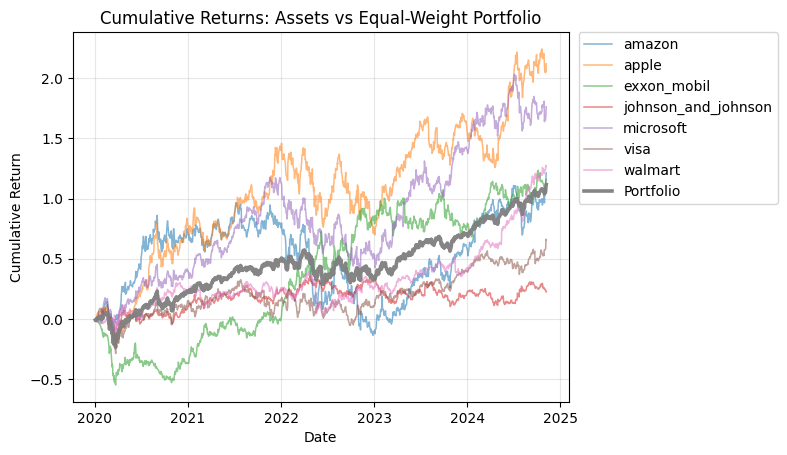

In [5]:
cumulative_returns = p1.show_cumulative_returns(log_returns)


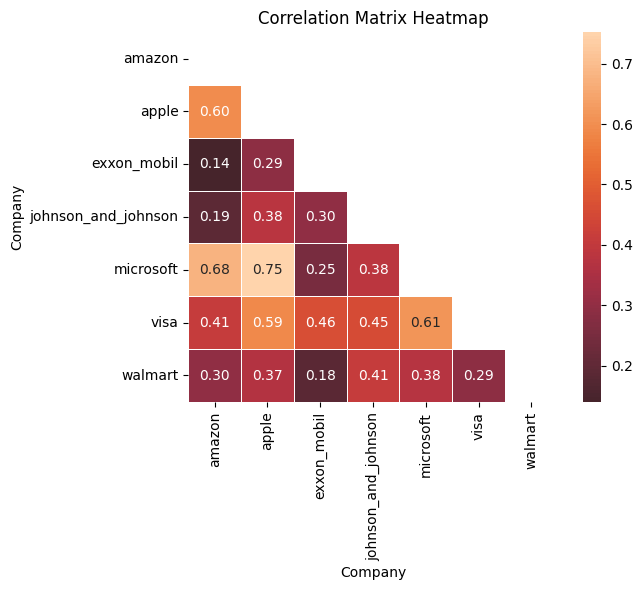

Company,amazon,apple,exxon_mobil,johnson_and_johnson,microsoft,visa,walmart
Company,,,,,,,
amazon,1.000000,0.596326,0.140066,0.188266,0.678563,0.411301,0.295466
apple,0.596326,1.000000,0.290028,0.378684,0.751999,0.587768,0.366180
exxon_mobil,0.140066,0.290028,1.000000,0.299832,0.251314,0.458329,0.183196
johnson_and_johnson,0.188266,0.378684,0.299832,1.000000,0.384142,0.453742,0.409313
microsoft,0.678563,0.751999,0.251314,0.384142,1.000000,0.613298,0.376091
visa,0.411301,0.587768,0.458329,0.453742,0.613298,1.000000,0.290058
walmart,0.295466,0.366180,0.183196,0.409313,0.376091,0.290058,1.000000


In [6]:
corr_matrix = p1.show_correlation(log_returns)


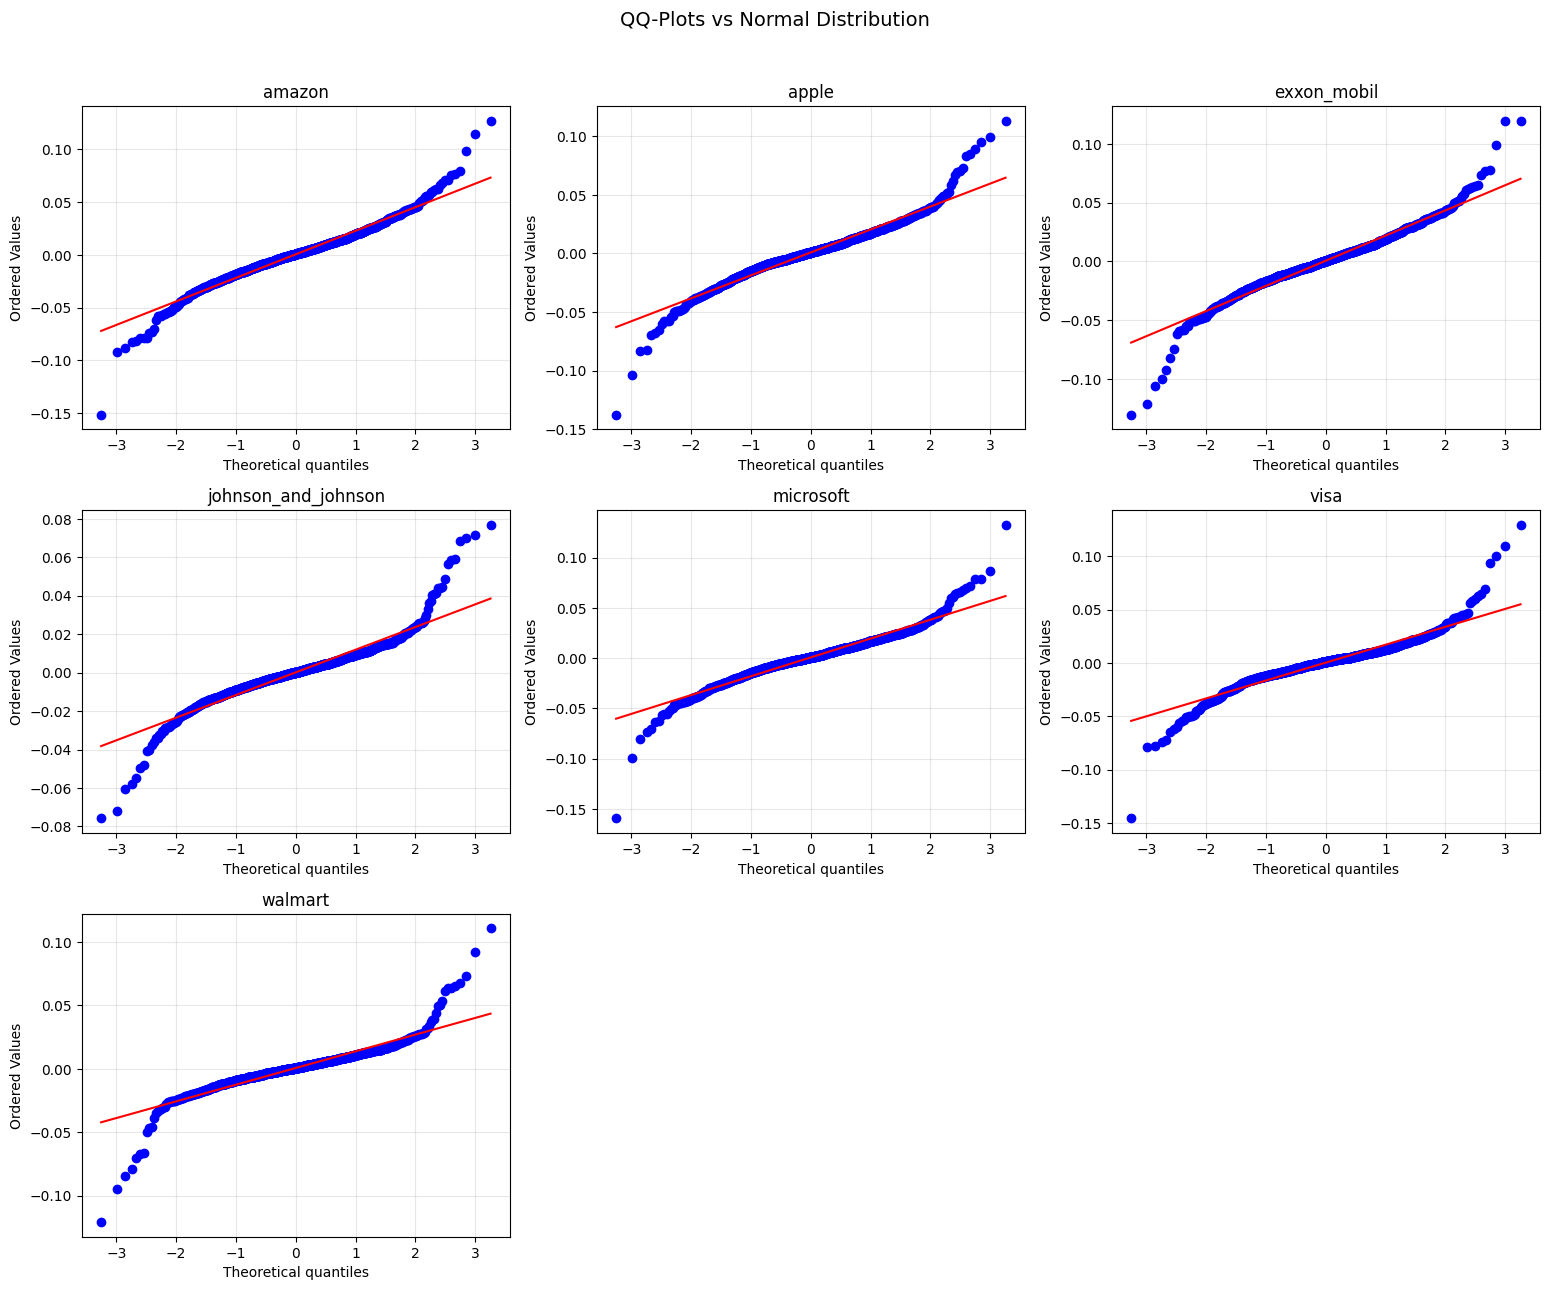

(                 Asset      Mean       Std      Skew  Excess_Kurtosis  \
 0               amazon  0.000651  0.022777 -0.126643         4.103251   
 1                apple  0.000932  0.020167 -0.104142         5.245444   
 2          exxon_mobil  0.000631  0.021909 -0.173571         4.538449   
 3  johnson_and_johnson  0.000165  0.012437  0.243608         8.086817   
 4            microsoft  0.000833  0.019401 -0.280703         7.461195   
 5                 visa  0.000412  0.017740 -0.043721        10.072497   
 6              walmart  0.000673  0.014276 -0.276250        14.533844   
 
     Emp_q05  Norm_q05  Ratio_q05   Emp_q01  Norm_q01  Ratio_q01       JB_stat  \
 0 -0.033707 -0.036814   0.915613 -0.057808 -0.052336   1.104547    850.788020   
 1 -0.031166 -0.032239   0.966708 -0.052660 -0.045983   1.145215   1387.974503   
 2 -0.033471 -0.035406   0.945358 -0.054273 -0.050337   1.078199   1043.202598   
 3 -0.017193 -0.020292   0.847310 -0.033587 -0.028768   1.167546   3307.915779

In [7]:
tail_df, cluster_df, limitations_txt = p1.distributional_analysis(log_returns)
tail_df, cluster_df


In [8]:
p1.report_key_results(tail_df, limitations_txt)


Key Results:
Stocks rejecting normality (5% JB): 7/7
Average tail ratio (1% empirical / normal): 1.12
Normality is a rough approximation: 7/7 assets reject Jarque–Bera at 5%. Tails are heavier than a fitted normal (avg empirical/theoretical tail ratio ≈ 1.02). Volatility clustering is present: 7/7 assets show significant Ljung–Box on squared returns.


In [9]:
p1.report_split(R_train, R_test, log_returns)


Data Split:
Train: 976 days (79.9%)
Test:  245 days (20.1%)
Split index: 2023-11-16 → 2023-11-17


In [10]:
p1.save_outputs('phase1_outputs.pkl',
    price_matrix=price_matrix, log_returns=log_returns, R_train=R_train,
    R_test=R_test, tickers=tickers, summary_stats=stats_df, corr_matrix=corr_matrix,
    tail_df=tail_df, cluster_df=cluster_df, limitations_txt=limitations_txt)


Saved: phase1_outputs.pkl


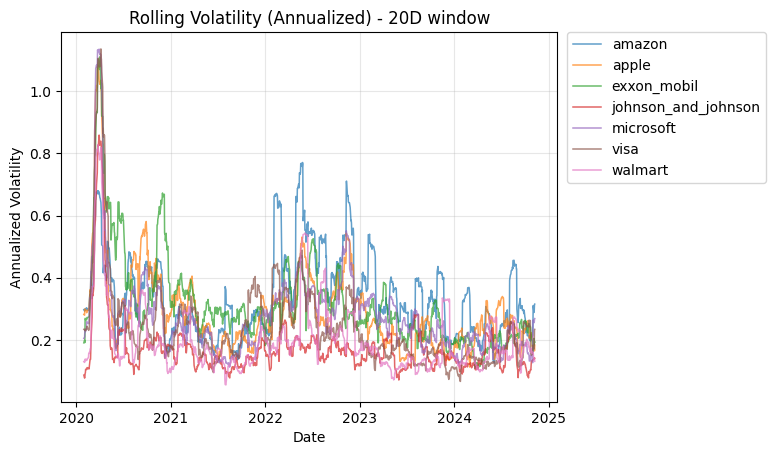

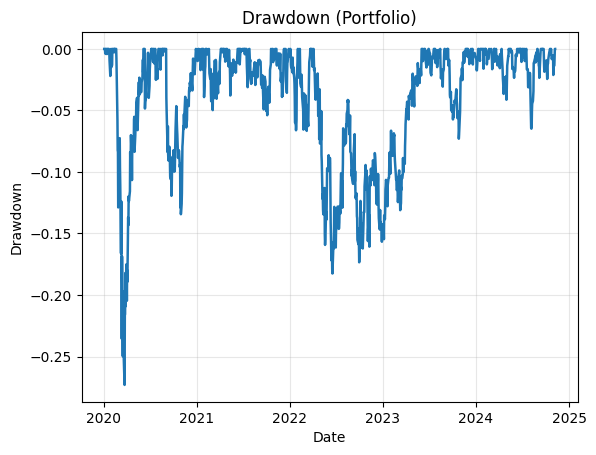

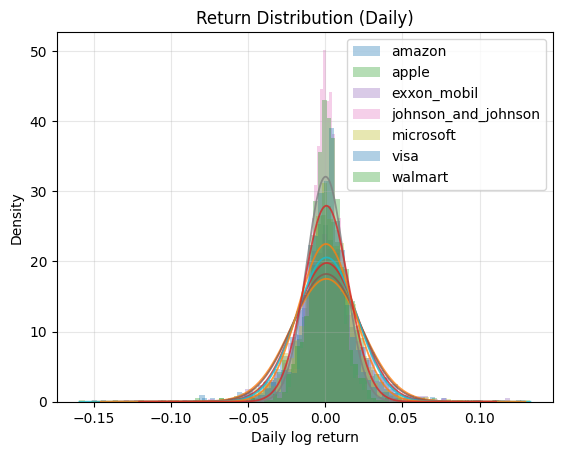

In [11]:
port_rets = p1.plot_risk_views(log_returns)


### 📝 Phase 1 summary — Data & exploratory analysis

**What I did:** Loaded 7 real stocks (2020–2024), built daily log returns, split 80/20 into train/test, and ran EDA: summary stats, correlation heatmap, QQ-plots, and fat-tail / volatility-clustering diagnostics.

**What the output means:** The QQ-plots and Jarque–Bera results show the returns are **not** normal (fat tails), and the correlation heatmap shows how the stocks co-move. Both findings motivate the simulation choices in the later phases.

# Phase 2

In [12]:
# Phase 2 — configuration
cfg2 = p2.Phase2Config(trading_days=252, seed=42,
    benchmark_draws=1_000_000, verify_sims=100_000)


In [13]:
R_train, R_test, tickers = p2.load_phase1('phase1_outputs.pkl')
R_train.head()


Train shape: (976, 7) | Test shape: (245, 7)


Company,amazon,apple,exxon_mobil,johnson_and_johnson,microsoft,visa,walmart
Date,,,,,,,
2020-01-03,-0.012213,-0.009769,-0.008072,-0.011646,-0.012530,-0.007985,-0.008867
2020-01-06,0.014776,0.007936,0.007649,-0.001248,0.002582,-0.002165,-0.002038
2020-01-07,0.002089,-0.004714,-0.008218,0.006088,-0.009159,-0.002646,-0.009308
2020-01-08,-0.007839,0.015958,-0.015195,-0.000138,0.015803,0.016973,-0.003437
2020-01-09,0.004788,0.021018,0.007627,0.002962,0.012416,0.006906,0.010277


In [14]:
mu_daily, sigma_daily, params_table = p2.estimate_params(R_train, trading_days=cfg2.trading_days)
params_table


,mu_daily,sigma_daily,mu_annual,vol_annual,sharpe_annual,skew,excess_kurtosis
Company,,,,,,,
amazon,0.000419,0.024006,0.105558,0.381087,0.276991,-0.102421,3.726098
apple,0.000976,0.021406,0.246048,0.339811,0.724073,-0.143267,4.823809
exxon_mobil,0.000591,0.023727,0.149028,0.376656,0.395659,-0.163186,3.806510
johnson_and_johnson,0.000131,0.013080,0.032911,0.207634,0.158505,0.220294,7.989232
microsoft,0.000910,0.020788,0.229289,0.329999,0.694817,-0.244003,6.767242
visa,0.000298,0.019133,0.075014,0.303733,0.246972,-0.002259,8.901283
walmart,0.000339,0.015046,0.085425,0.238845,0.357660,-0.402795,13.940246


In [15]:
params_table[['mu_annual','vol_annual','sharpe_annual']].sort_values('sharpe_annual', ascending=False)


,mu_annual,vol_annual,sharpe_annual
Company,,,
apple,0.246048,0.339811,0.724073
microsoft,0.229289,0.329999,0.694817
exxon_mobil,0.149028,0.376656,0.395659
walmart,0.085425,0.238845,0.357660
amazon,0.105558,0.381087,0.276991
visa,0.075014,0.303733,0.246972
johnson_and_johnson,0.032911,0.207634,0.158505


In [16]:
cov_diag = p2.covariance_diagnostics(sigma_daily, tol=cfg2.posdef_tol)
cov_diag


,min_eigenvalue,max_eigenvalue,is_positive_definite,condition_number
0,0.00009,0.001525,True,16.919733


In [17]:
sim = p2.benchmark_and_simulate(mu_daily, sigma_daily, cfg2)
comparison_df    = sim['comparison_df']
sim_bm, sim_mp   = sim['sim_bm'], sim['sim_mp']
L_bm, L_mp       = sim['L_bm'], sim['L_mp']
chol_info_bm, chol_info_mp = sim['chol_info_bm'], sim['chol_info_mp']
diag_bm, diag_mp = sim['diag_bm'], sim['diag_mp']
comparison_df


,method,n,seconds,mean,var,speed_normals_per_sec
0,Box–Muller,1000000,0.059183,-0.001390,1.001305,1.689680e+07
1,Marsaglia Polar,1000000,0.095508,-0.000325,0.999932,1.047036e+07


In [18]:
comparison_df


,method,n,seconds,mean,var,speed_normals_per_sec
0,Box–Muller,1000000,0.059183,-0.001390,1.001305,1.689680e+07
1,Marsaglia Polar,1000000,0.095508,-0.000325,0.999932,1.047036e+07


In [19]:
p2.report_cholesky(chol_info_bm, chol_info_mp, L_mp, tickers)


Cholesky jitter info (Box–Muller): {'added_jitter': 0.0, 'tries': 1.0}
Cholesky jitter info (Marsaglia): {'added_jitter': 0.0, 'tries': 1.0}


,amazon,apple,exxon_mobil,johnson_and_johnson,microsoft,visa,walmart
amazon,0.0240,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
apple,0.0134,0.0167,0.0000,0.0000,0.0000,0.0000,0.0000
exxon_mobil,0.0038,0.0067,0.0225,0.0000,0.0000,0.0000,0.0000
johnson_and_johnson,0.0030,0.0048,0.0024,0.0115,0.0000,0.0000,0.0000
microsoft,0.0142,0.0094,0.0010,0.0024,0.0116,0.0000,0.0000
visa,0.0082,0.0089,0.0057,0.0035,0.0035,0.0128,0.0000
walmart,0.0047,0.0040,0.0012,0.0043,0.0009,-0.0009,0.0129


In [20]:
diag_bm.rename(index={0:'Box–Muller'}), diag_mp.rename(index={0:'Marsaglia Polar'})


(            frobenius_rel_error  max_abs_error  mean_abs_error
 Box–Muller             0.004574       0.000003    8.925325e-07,
                  frobenius_rel_error  max_abs_error  mean_abs_error
 Marsaglia Polar             0.006985       0.000006        0.000001)

In [21]:
bm_stats, mp_stats = p2.simulated_describe(sim_bm, sim_mp)
bm_stats, mp_stats


(                         mean       std       min       max
 amazon               0.000365  0.024048 -0.107913  0.106834
 apple                0.000936  0.021464 -0.097789  0.098317
 exxon_mobil          0.000502  0.023674 -0.102683  0.102317
 johnson_and_johnson  0.000067  0.013084 -0.060617  0.061830
 microsoft            0.000877  0.020762 -0.089506  0.095663
 visa                 0.000300  0.019099 -0.078688  0.084059
 walmart              0.000250  0.015005 -0.058923  0.065489,
                          mean       std       min       max
 amazon               0.000324  0.023895 -0.113262  0.096561
 apple                0.000928  0.021405 -0.090585  0.088101
 exxon_mobil          0.000572  0.023844 -0.104383  0.099648
 johnson_and_johnson  0.000101  0.013049 -0.057436  0.060855
 microsoft            0.000898  0.020782 -0.091967  0.091965
 visa                 0.000258  0.019081 -0.089017  0.083324
 walmart              0.000366  0.015123 -0.062356  0.063416)

### Monte Carlo fan chart — simulated portfolio value paths

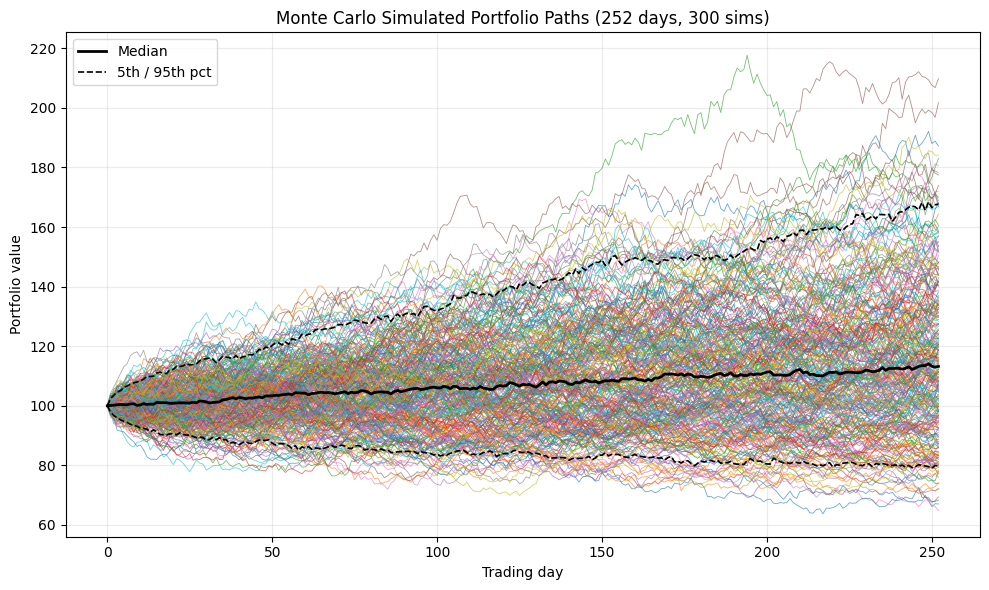

Simulated 300 paths over 252 days | terminal value: median=113.23, 5-95% range=[79.77, 167.65]


In [22]:
paths = p2.show_price_paths(mu_daily, sigma_daily, weights=None,
    n_paths=300, horizon_days=252, initial_value=100.0, seed=42)


In [23]:
p2.save_outputs('phase2_outputs.pkl',
    mu_daily=mu_daily, sigma_daily=sigma_daily, params_table=params_table,
    cov_diag=cov_diag, comparison_df=comparison_df, simulated_bm=sim_bm,
    simulated_mp=sim_mp, L_bm=L_bm, L_mp=L_mp, chol_info_bm=chol_info_bm,
    chol_info_mp=chol_info_mp, diagnostics_bm=diag_bm, diagnostics_mp=diag_mp,
    tickers=tickers)


Saved: phase2_outputs.pkl


### 📝 Phase 2 summary — Core simulation engine

**What I did:** Estimated the mean vector μ and covariance Σ from the training data, implemented the Box–Muller and Marsaglia–Polar normal generators, and used Cholesky decomposition to draw **correlated** multivariate-normal returns.

**What the output means:** The verification table shows the simulated covariance matches the historical Σ, confirming the engine reproduces the real correlation structure. The fan chart shows many plausible 1-year portfolio value paths fanning out from today.

# Phase 3

In [24]:
mu_daily, sigma_daily, R_train = p3.load_inputs('phase1_outputs.pkl', 'phase2_outputs.pkl')


  Parameters loaded | Assets: 7 | Train data shape: (976, 7)


In [25]:
n_sims, horizon_days, n_assets, equal_weights = p3.equal_weight_setup(R_train, n_sims=10000, horizon_days=10)


Simulations: 10000 | Horizon: 10 days | Assets: 7


In [26]:
mvn_result = p3.module_3_1_multivariate_normal(
    mu_daily, sigma_daily, n_sims=n_sims, horizon_days=horizon_days,
    portfolio_weights=equal_weights)


In [27]:
bootstrap_result = p3.module_3_2_historical_bootstrap(
    R_train, n_sims=n_sims, horizon_days=horizon_days, portfolio_weights=equal_weights)


In [28]:
regime_result = p3.module_3_3_regime_switching_mvn(
    mu_daily, sigma_daily, n_sims=n_sims, horizon_days=horizon_days,
    portfolio_weights=equal_weights, p_normal=0.9, k_stress=3.0)


### Model D — Student-t copula (fat-tailed scenarios)

In [29]:
student_t_result = p3.module_3_5_student_t_copula(
    R_train, n_sims=n_sims, horizon_days=horizon_days,
    portfolio_weights=equal_weights, copula='t')
p3.report_marginal_dfs(student_t_result)


Lower df = heavier tails (df>30 ≈ Normal). Copula: t


,Asset,fitted_df,loc,scale
0,apple,4.000000,0.001298,0.015117
1,johnson_and_johnson,4.000000,0.000155,0.007764
2,visa,4.000000,0.000677,0.011764
3,microsoft,4.000000,0.001164,0.014619
4,walmart,4.000000,0.000537,0.008572
5,amazon,4.289841,0.000559,0.017787
6,exxon_mobil,4.641717,0.000633,0.017920


,Asset,fitted_df,loc,scale
0,apple,4.000000,0.001298,0.015117
1,johnson_and_johnson,4.000000,0.000155,0.007764
2,visa,4.000000,0.000677,0.011764
3,microsoft,4.000000,0.001164,0.014619
4,walmart,4.000000,0.000537,0.008572
5,amazon,4.289841,0.000559,0.017787
6,exxon_mobil,4.641717,0.000633,0.017920


In [30]:
model_results = p3.collect_models(mvn_result, bootstrap_result, regime_result,
    student_t_result=student_t_result)


Models prepared: ['MVN', 'Historical_Bootstrap', 'Regime_Switching_MVN', 'Student_t_Copula']
  MVN: (10000, 7) scenarios
  Historical_Bootstrap: (10000, 7) scenarios
  Regime_Switching_MVN: (10000, 7) scenarios
  Student_t_Copula: (10000, 7) scenarios


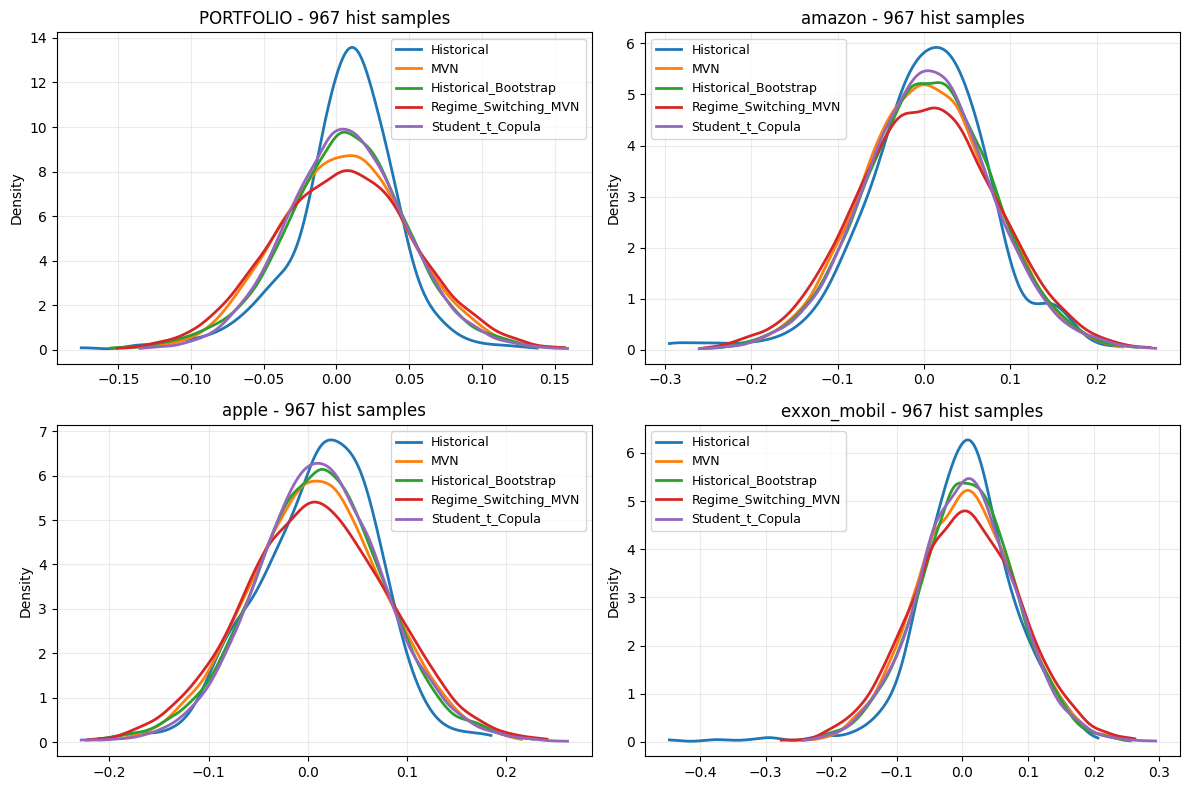

In [31]:
comparison_results = p3.module_3_4_model_comparison(
    historical_returns=R_train, model_results=model_results,
    horizon_days=horizon_days, portfolio_weights=equal_weights)


In [32]:
p3.report_key_results(comparison_results)



Portfolio Metrics Comparison:
               Model     Mean      Std   VaR_95%   VaR_99%
          Historical 0.005270 0.038063 -0.061840 -0.111413
                 MVN 0.004664 0.044892 -0.068561 -0.099887
Historical_Bootstrap 0.005825 0.044452 -0.068719 -0.109549
Regime_Switching_MVN 0.004430 0.049221 -0.076477 -0.110406
    Student_t_Copula 0.006698 0.042114 -0.061645 -0.092882

Best Model: Regime_Switching_MVN


In [33]:
p3.report_tail_properties(comparison_results, R_train)



Tail Properties for amazon:

Historical:
  95% VaR: -11.38%
  99% VaR: -24.14%
  CVaR 95%: -17.69%
  Excess Kurtosis: 1.78

MVN:
  95% VaR: -11.98%
  99% VaR: -17.24%
  CVaR 95%: -15.19%
  Excess Kurtosis: -0.02

Historical_Bootstrap:
  95% VaR: -11.95%
  99% VaR: -17.96%
  CVaR 95%: -15.60%
  Excess Kurtosis: 0.24

Regime_Switching_MVN:
  95% VaR: -13.21%
  99% VaR: -19.43%
  CVaR 95%: -16.86%
  Excess Kurtosis: 0.07


In [34]:
p3.save_outputs('phase3_outputs.pkl',
    mvn_result=mvn_result, bootstrap_result=bootstrap_result, regime_result=regime_result,
    comparison_results=comparison_results,
    config={'n_sims': n_sims, 'horizon_days': horizon_days, 'weights': equal_weights})


Saved: phase3_outputs.pkl


### 📝 Phase 3 summary — Scenario generation models

**What I did:** Generated forward-return scenarios under four models — multivariate Normal, historical bootstrap, regime-switching, and a Student-t copula — then compared their distributions against the real data.

**What the output means:** The comparison table/figure shows which model best matches the historical tails. The Normal understates extreme losses, while the Student-t copula (fitted df ≈ 4) captures the fat tails the EDA found.

# Phase 4

In [35]:
mu_daily, sigma_daily, tickers = p4.load_inputs('phase2_outputs.pkl')


  Parameters loaded | Assets: 7


In [36]:
weights, horizon_days, theoretical_mean, theoretical_vol = p4.theoretical_portfolio(
    mu_daily, sigma_daily, tickers, horizon_days=10)


Theoretical 10-day portfolio: Mean=0.005234 | Vol=0.044567


In [37]:
conv_results, conv_info = p4.convergence_analysis(
    mu_daily, sigma_daily, weights=weights, horizon_days=horizon_days,
    n_grid=(100, 1_000, 10_000, 100_000), alpha=0.95, seed=42,
    method='marsaglia_polar', benchmark_theoretical=True)
display(conv_results)


,N,SE_Mean,Mean,Volatility,VaR_95%,CVaR_95%,Abs_Error_Mean,Abs_Error_Vol,Abs_Error_VaR,Abs_Error_CVaR
0,100,0.004558,0.014085,0.045575,0.063646,0.084487,0.008851,0.001009,0.004426,0.002208
1,1000,0.001400,0.006481,0.044260,0.066414,0.084023,0.001247,0.000307,0.001658,0.002671
2,10000,0.000450,0.005993,0.045003,0.067250,0.086555,0.000759,0.000436,0.000821,0.000139
3,100000,0.000141,0.005325,0.044448,0.067712,0.086484,0.000091,0.000119,0.000360,0.000210


In [38]:
p4.report_convergence_summary(conv_results)



Convergence (largest N=100000):
  Mean: 0.005325 (AbsErr: 9.11e-05, SE: 1.41e-04)
  Volatility: 0.044448 (AbsErr: 1.19e-04)
  95% VaR (Loss): 0.067712 (AbsErr: 3.60e-04)
  95% CVaR (Loss): 0.086484 (AbsErr: 2.10e-04)


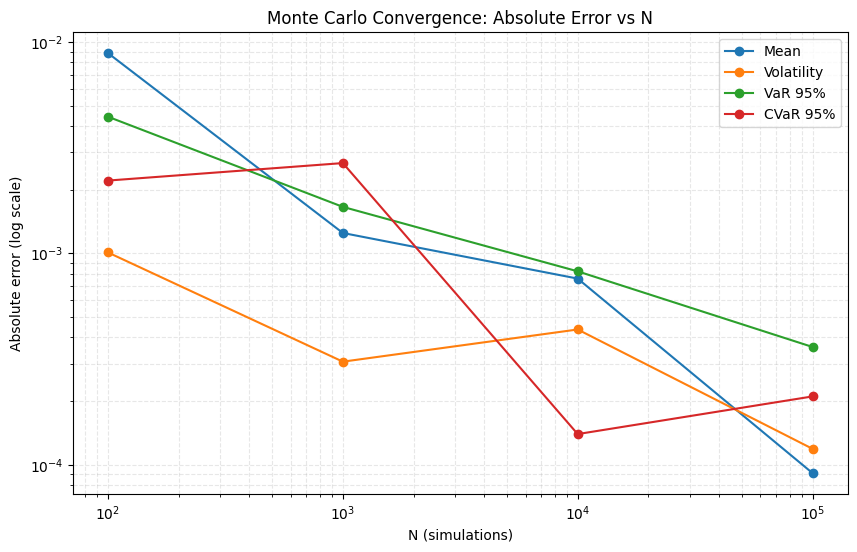

In [39]:
p4.show_convergence_errors(conv_results, alpha=0.95)


### Famous MC convergence graph — running estimate → true value with 95% CI band

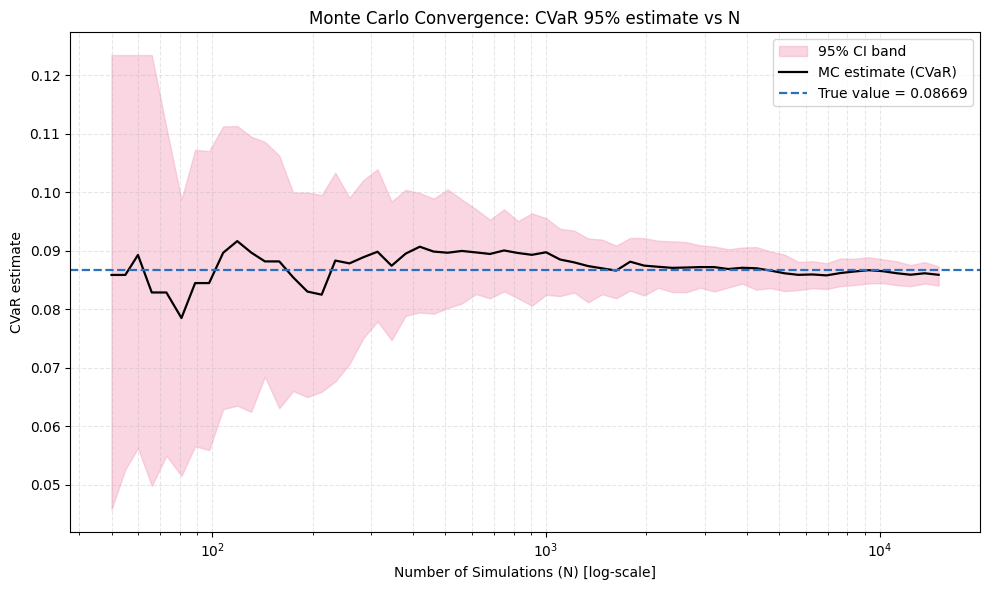

In [40]:
conv_path = p4.running_convergence(mu_daily, sigma_daily, weights=weights,
    horizon_days=horizon_days, N_max=15_000, alpha=0.95, metric='CVaR', seed=42)
p4.show_running_convergence(conv_path, metric='CVaR', alpha=0.95)


In [41]:
ci_results = p4.confidence_intervals(
    mu_daily, sigma_daily, weights=weights, horizon_days=horizon_days,
    N=10_000, B=1_000, alpha=0.95, seed=42, method='marsaglia_polar', ci_level=0.95)
display(ci_results['point_estimates'])
display(ci_results['results_table'])
display(ci_results['bootstrap_samples'].head())


{'Mean': 0.004940500029640269,
 'Volatility': 0.04443927683855129,
 'VaR_95%': 0.06799076427539907,
 'CVaR_95%': 0.08669923534594588}

,Metric,Point_Estimate,CI_Lower,CI_Upper,CI_Width
0,Mean,0.004941,0.004015,0.005800,0.001785
1,Volatility,0.044439,0.043806,0.045034,0.001228
2,VaR_95%,0.067991,0.065773,0.069807,0.004034
3,CVaR_95%,0.086699,0.084420,0.088780,0.004359


,Mean,Volatility,VaR_95%,CVaR_95%
0,0.004585,0.044090,0.067289,0.087018
1,0.005198,0.044247,0.066572,0.085931
2,0.005226,0.044448,0.068756,0.088025
3,0.004788,0.044722,0.065642,0.084757
4,0.005651,0.044268,0.069096,0.086719


In [42]:
p4.report_confidence_intervals(ci_results)


,Metric,Point_Estimate,CI_Lower,CI_Upper,CI_Width,Relative_Width
0,Mean,0.004941,0.004015,0.005800,0.001785,0.361244
1,Volatility,0.044439,0.043806,0.045034,0.001228,0.027636
2,VaR_95%,0.067991,0.065773,0.069807,0.004034,0.059339
3,CVaR_95%,0.086699,0.084420,0.088780,0.004359,0.050280



Point Estimates with 95% Confidence Intervals:

Mean:
  Point Estimate: 0.004941
  95% CI: [0.004015, 0.005800]
  CI Width: 0.001785
  Relative Width: 36.12%

Volatility:
  Point Estimate: 0.044439
  95% CI: [0.043806, 0.045034]
  CI Width: 0.001228
  Relative Width: 2.76%

VaR_95%:
  Point Estimate: 0.067991
  95% CI: [0.065773, 0.069807]
  CI Width: 0.004034
  Relative Width: 5.93%

CVaR_95%:
  Point Estimate: 0.086699
  95% CI: [0.084420, 0.088780]
  CI Width: 0.004359
  Relative Width: 5.03%


In [43]:
p4.print_ci_method_notes()


Why Bootstrap Percentile CIs are Preferred for VaR/CVaR:
1. No distributional assumptions required
2. Automatically handles non-normal statistics
3. Captures asymmetry in sampling distributions
4. More robust for tail risk measures
5. Easy to implement and interpret

For Mean and Volatility:
• CLT-based CIs are valid for large N
• But bootstrap CIs provide consistency
• Bootstrap works well even when CLT assumptions are questionable


In [44]:
p4.report_bootstrap_distributions(ci_results)



Bootstrap Distribution Statistics:

Mean:
  Mean: 0.004935
  Std: 0.000455
  Skewness: -0.0251
  Kurtosis: -0.0826

Volatility:
  Mean: 0.044429
  Std: 0.000310
  Skewness: 0.0352
  Kurtosis: 0.2075

VaR_95%:
  Mean: 0.067895
  Std: 0.001112
  Skewness: -0.2671
  Kurtosis: -0.4067

CVaR_95%:
  Mean: 0.086681
  Std: 0.001122
  Skewness: -0.1162
  Kurtosis: -0.1241


In [45]:
p4.save_outputs('phase4_outputs.pkl',
    convergence_results=conv_results, confidence_intervals=ci_results,
    config={'horizon_days': horizon_days, 'weights': weights,
            'theoretical_mean': theoretical_mean, 'theoretical_vol': theoretical_vol},
    info=conv_info)


Saved: phase4_outputs.pkl


### 📝 Phase 4 summary — Monte Carlo convergence

**What I did:** Re-ran the simulation with growing N (100 → 100,000) and tracked how the mean, volatility, VaR and CVaR estimates converge, with bootstrap confidence intervals.

**What the output means:** The log-log plot's slope ≈ −0.5 confirms the textbook 1/√N Monte Carlo convergence rate, and the running-estimate plot shows the estimate settling onto the true value as its 95% confidence band shrinks.

# Phase 5

In [46]:
mu_daily, sigma_daily, mu_annual, sigma_annual, tickers = p5.load_and_annualize(
    'phase2_outputs.pkl', trading_days=252, risk_free=0.04)
risk_free = 0.04


Assets: 7 | Annual return range: 3.29% to 24.60%
Average correlation: 0.427


In [47]:
cfg_m = p5.MarkowitzConfig(n_points=20, risk_free=risk_free)
frontier_df, min_vol_weights_mv, max_sharpe_weights_mv = p5.markowitz_frontier(
    mu_annual, sigma_annual, cfg=cfg_m)
weights = max_sharpe_weights_mv.copy()
target_weights = max_sharpe_weights_mv.copy()
portfolio_name = 'Max Sharpe Portfolio (Markowitz)'


In [48]:
p5.report_markowitz(frontier_df, min_vol_weights_mv, max_sharpe_weights_mv)


Efficient Frontier (first 10 points):


,return,volatility,sharpe
0,0.032911,0.207634,-0.034142
1,0.044129,0.190729,0.021647
2,0.055347,0.182912,0.083901
3,0.066564,0.180928,0.146822
4,0.077782,0.182590,0.206922
5,0.089000,0.185217,0.264553
6,0.100217,0.188740,0.319049
7,0.111435,0.193112,0.369916
8,0.122653,0.198449,0.416495
9,0.133871,0.204808,0.458334



Min-Vol weights:


,amazon,apple,exxon_mobil,johnson_and_johnson,microsoft,visa,walmart
min_vol,0.083505,0.0,0.082364,0.509973,0.0,0.019249,0.304908



Max-Sharpe weights:


,amazon,apple,exxon_mobil,johnson_and_johnson,microsoft,visa,walmart
max_sharpe,1.898260e-17,0.525523,0.122223,0.0,0.352254,1.622469e-16,0.0



Weights comparison:


,min_vol,max_sharpe
amazon,0.083505,1.898260e-17
apple,0.000000,5.255230e-01
exxon_mobil,0.082364,1.222233e-01
johnson_and_johnson,0.509973,0.000000e+00
microsoft,0.000000,3.522537e-01
visa,0.019249,1.622469e-16
walmart,0.304908,0.000000e+00


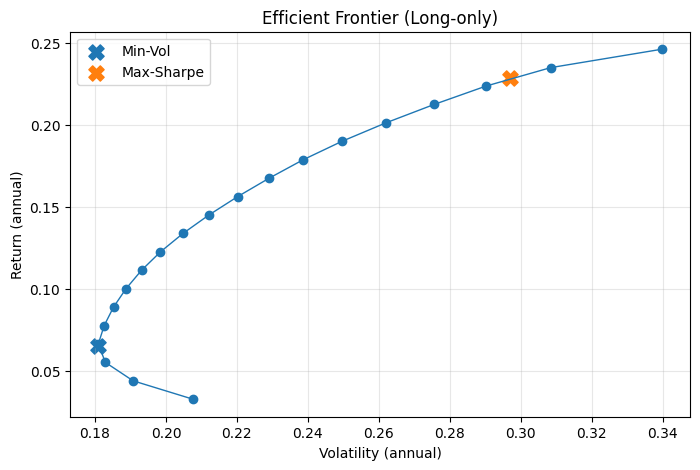

In [49]:
p5.plot_efficient_frontier(frontier_df, mu_annual, sigma_annual,
    min_vol_weights_mv, max_sharpe_weights_mv)


In [50]:
out = p5.select_frontier_preview(frontier_df, mu_annual)


Selected frontier portfolios + weights:


,return,volatility,sharpe,amazon,apple,exxon_mobil,johnson_and_johnson,microsoft,visa,walmart
0,0.032911,0.207634,-0.034142,1.051495e-17,0.000000,3.873226e-17,1.000000,0.000000e+00,1.745796e-16,7.346486e-17
1,0.145088,0.212098,0.495471,2.041266e-18,0.188039,1.533391e-01,0.151365,1.922364e-01,2.792908e-18,3.150204e-01
2,0.246048,0.339811,0.606361,0.000000e+00,1.000000,7.711854e-17,0.000000,6.578542e-13,3.890851e-17,1.764642e-17


In [51]:
cfg_mc = p5.MCOptConfig(n_portfolios=10_000, n_sims=5_000, horizon_days=10, seed=42)
mc_results = p5.mc_optimization(mu_annual, sigma_annual, frontier_df=frontier_df, cfg=cfg_mc)
p5.report_mc_summary(mc_results, cfg_mc)


Total portfolios evaluated: 10,000
Annual return range: 4.51% to 23.67%
Annual volatility range: 18.16% to 35.29%
Sharpe range: 0.025 to 0.617
10-day VaR(95%) range: 0.0561 to 0.1115
10-day CVaR(95%) range: 0.0704 to 0.1405

Optima:
  Max Sharpe (MC): 0.6169844034072434
  Min CVaR_95 (MC): 0.07044727368171952


,Max_Sharpe_MC,Min_CVaR_MC
amazon,0.009847,0.074631
apple,0.615355,0.008109
exxon_mobil,0.064022,0.082378
johnson_and_johnson,0.006689,0.558728
microsoft,0.245148,0.002813
visa,0.019130,0.024260
walmart,0.039809,0.249081


In [52]:
p5.report_markowitz_vs_mc(max_sharpe_weights_mv, mc_results, mu_annual, sigma_annual, risk_free)


Metric          Markowitz    Monte Carlo  Difference  
-------------------------------------------------------
Return          22.83%      22.33%      -0.50%
Volatility      29.70%      29.70%      -0.00%
Sharpe          0.634      0.617      -0.017


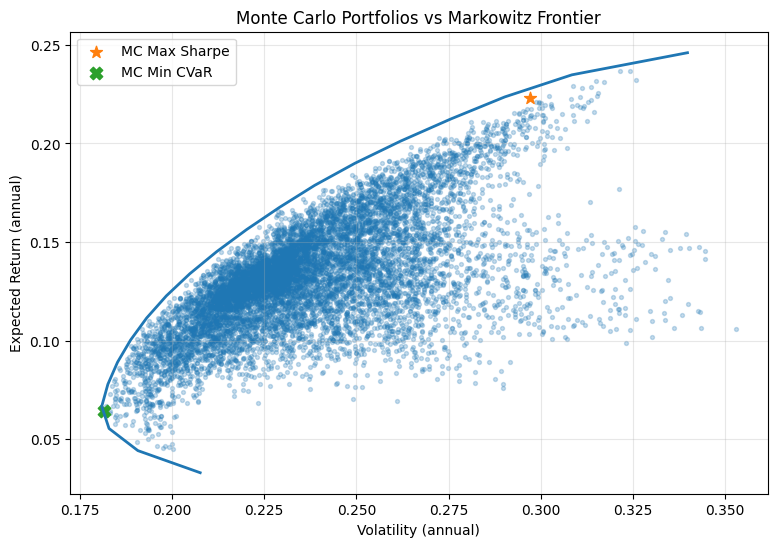

In [53]:
p5.plot_mc_scatter(mc_results, frontier_df, mu_annual, sigma_annual, risk_free)


In [54]:
display(mc_results['pareto_mv'].head(15))
display(mc_results['pareto_cvar'].head(15))


,return_ann,vol_ann,sharpe,return_H,var_95,cvar_95,var_99,cvar_99
1674,0.236722,0.321483,0.611921,0.008798,0.097927,0.123527,0.138610,0.164019
4773,0.231903,0.315001,0.609215,0.008566,0.096627,0.121036,0.135078,0.160166
5067,0.229344,0.308664,0.613432,0.008461,0.094030,0.118406,0.135889,0.157022
6223,0.224321,0.302189,0.609951,0.008255,0.091718,0.116013,0.134383,0.153721
2042,0.223253,0.297014,0.616984,0.008171,0.090236,0.114113,0.131684,0.151140
7783,0.217679,0.296394,0.599469,0.008001,0.089201,0.114087,0.132608,0.150609
7181,0.216335,0.295296,0.597146,0.007953,0.090187,0.113316,0.127996,0.149999
4390,0.215427,0.292779,0.599180,0.007855,0.089144,0.112833,0.128520,0.148737
2269,0.211337,0.287755,0.595426,0.007721,0.087740,0.110374,0.125670,0.145667
4621,0.210945,0.284240,0.601411,0.007646,0.086367,0.109078,0.123299,0.143415


,return_ann,vol_ann,sharpe,return_H,var_95,cvar_95,var_99,cvar_99
1674,0.236722,0.321483,0.611921,0.008798,0.097927,0.123527,0.138610,0.164019
4773,0.231903,0.315001,0.609215,0.008566,0.096627,0.121036,0.135078,0.160166
5067,0.229344,0.308664,0.613432,0.008461,0.094030,0.118406,0.135889,0.157022
6223,0.224321,0.302189,0.609951,0.008255,0.091718,0.116013,0.134383,0.153721
2042,0.223253,0.297014,0.616984,0.008171,0.090236,0.114113,0.131684,0.151140
7783,0.217679,0.296394,0.599469,0.008001,0.089201,0.114087,0.132608,0.150609
7181,0.216335,0.295296,0.597146,0.007953,0.090187,0.113316,0.127996,0.149999
9884,0.215396,0.294063,0.596460,0.007889,0.088156,0.112895,0.129904,0.148460
4390,0.215427,0.292779,0.599180,0.007855,0.089144,0.112833,0.128520,0.148737
2269,0.211337,0.287755,0.595426,0.007721,0.087740,0.110374,0.125670,0.145667


In [55]:
p5.save_outputs('phase5_outputs.pkl', 'phase5_comprehensive_summary.csv',
    frontier_df=frontier_df, min_vol_weights_mv=min_vol_weights_mv,
    max_sharpe_weights_mv=max_sharpe_weights_mv, mc_results=mc_results,
    tickers=tickers, mu_annual=mu_annual, sigma_annual=sigma_annual)


Saved: phase5_outputs.pkl
Saved: phase5_comprehensive_summary.csv


In [56]:
p5.print_takeaways()


• Markowitz frontier gives the long-only efficient trade-off between return and volatility.
• MC optimization uses common random numbers to reduce noise when comparing candidate portfolios.
• MC Max-Sharpe should be close to Markowitz Max-Sharpe; MC Min-CVaR shifts toward downside risk reduction.


### 📝 Phase 5 summary — Portfolio optimization (the core comparison)

**What I did:** Built the Markowitz efficient frontier (analytical) and a Monte Carlo random-portfolio search, compared the two, and identified the max-Sharpe and min-CVaR portfolios.

**What the output means:** The MC scatter sits under the Markowitz frontier (the frontier is the efficient upper edge), and the comparison table shows the MC max-Sharpe portfolio lands close to Markowitz — validating the Monte Carlo approach against the classic one.

# Phase 6

In [57]:
# Phase 6 - VaR/CVaR. p=0.90 / k=3.0 are the Model C (regime-switching)
# parameters; cvar_integral_check adds the CVaR identity cross-check columns.
cfg6 = p6.Phase6Config(n_sims=10_000, horizon_days=10, alphas=(0.95, 0.99),
    seed=42, p=0.90, k=3.0, cvar_integral_check=True)
phase6_results = p6.run_phase6(R_train=R_train, mu_daily=mu_daily, sigma_daily=sigma_daily,
    weights=weights, cfg=cfg6, include_historical=True,
    save_dir='outputs/phase6', prefix='phase6', save_plots=True)
phase6_results['risk_table']


,model,alpha,VaR,CVaR,CVaR_identity,CVaR_abs_diff,CVaR_rel_diff
0,Model A (MVN),0.95,0.088802,0.112908,0.112908,1.387779e-17,1.229129e-16
1,Model A (MVN),0.99,0.128117,0.148957,0.148957,0.000000e+00,0.000000e+00
2,Model B (Bootstrap),0.95,0.091152,0.125047,0.125047,2.775558e-17,2.219613e-16
3,Model B (Bootstrap),0.99,0.146036,0.179572,0.179572,0.000000e+00,0.000000e+00
4,Model C (Mixture MVN),0.95,0.097665,0.124953,0.124953,2.775558e-17,2.221276e-16
5,Model C (Mixture MVN),0.99,0.142852,0.165310,0.165310,2.775558e-17,1.678997e-16
6,Historical (rolling 10d),0.95,0.077913,0.116136,0.116650,5.138537e-04,4.424596e-03
7,Historical (rolling 10d),0.99,0.140508,0.182604,0.184040,1.436574e-03,7.867172e-03


In [58]:
p6.report_results(phase6_results, portfolio_name)


Portfolio: Max Sharpe Portfolio (Markowitz)
Weights (aligned):


,amazon,apple,exxon_mobil,johnson_and_johnson,microsoft,visa,walmart
weight,1.898260e-17,0.525523,0.122223,0.0,0.352254,1.622469e-16,0.0



VaR/CVaR table (portfolio, 10-day loss):


VaR                CVaR          
alpha                         0.95      0.99      0.95      0.99
model                                                           
Historical (rolling 10d)  0.077913  0.140508  0.116136  0.182604
Model A (MVN)             0.088802  0.128117  0.112908  0.148957
Model B (Bootstrap)       0.091152  0.146036  0.125047  0.179572
Model C (Mixture MVN)     0.097665  0.142852  0.124953  0.165310

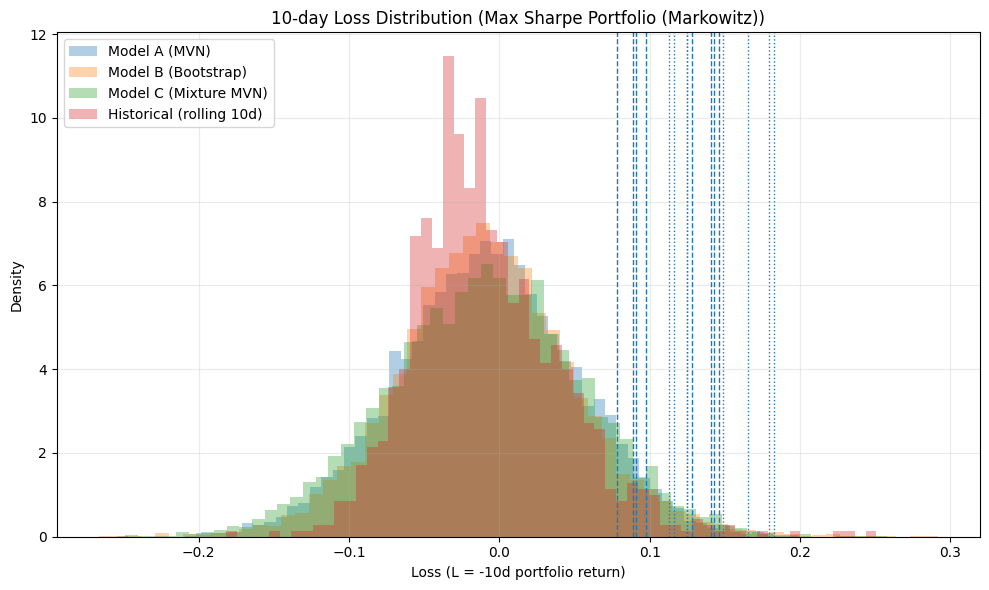

In [59]:
p6.show_loss_distributions(phase6_results, portfolio_name)


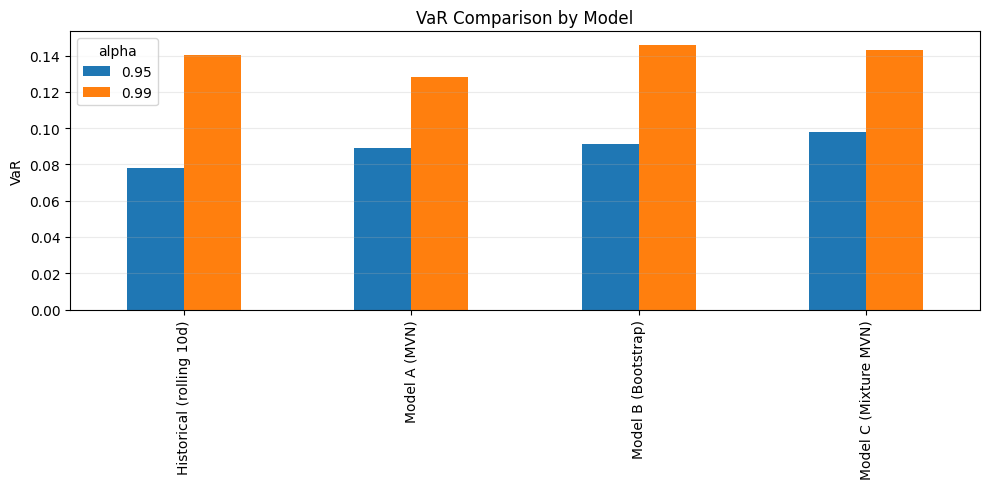

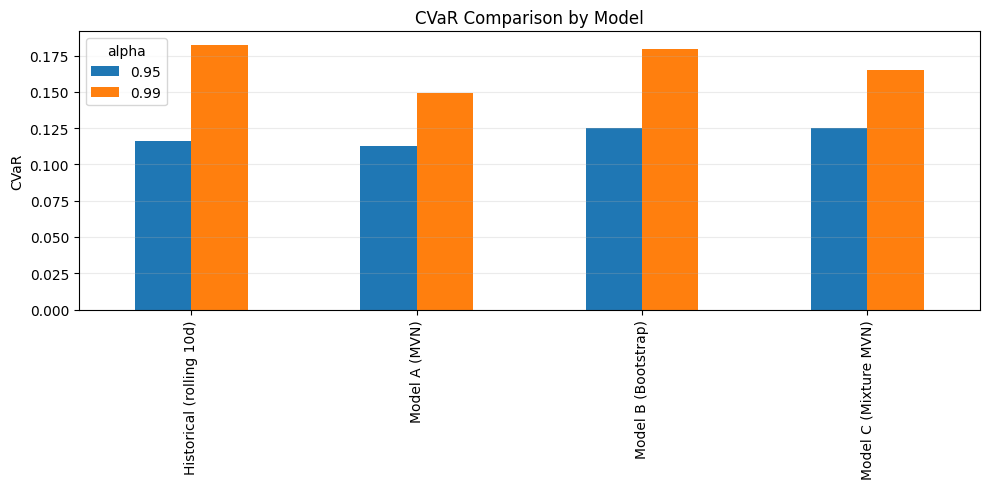

In [60]:
p6.show_risk_bars(phase6_results)


In [61]:
p6.save_outputs(phase6_results, 'phase6_outputs.pkl')


Saved: phase6_outputs.pkl


### 📝 Phase 6 summary — Risk metrics (VaR & CVaR)

**What I did:** Estimated 10-day VaR and CVaR at 95% and 99% for the chosen portfolio under each scenario model, with a CVaR identity cross-check.

**What the output means:** The table shows how much could be lost over a bad 10 days. CVaR is always ≥ VaR (it is the **average** loss beyond VaR), and the spread across models shows how sensitive the risk estimate is to the model you trust.

# Phase 7

In [62]:
# Phase 7 — Variance Reduction


In [63]:
cfg7 = p7.Phase7Config(horizon_days=10, alphas=(0.95, 0.99), N=20_000, reps=30,
    seed=42, is_enabled=True, is_shift_sigmas=2.0, N_grid=(100, 1_000, 10_000, 100_000))
phase7_results = p7.run_phase7(mu_daily, sigma_daily, weights, cfg=cfg7)


In [64]:
p7.report(phase7_results)



Phase 7 summary table (variance / CI width / VRF / ESS):


,method,metric,estimate_mean,estimate_sd,estimate_var,ess_mean,ci_halfwidth,ci_width,vrf_vs_crude,ess_ratio
0,antithetic,CVaR_95,0.113071,0.000965,9.316943e-07,NaN,0.001892,0.003784,1.199794,NaN
1,crude,CVaR_95,0.113153,0.001057,1.117842e-06,NaN,0.002072,0.004144,1.000000,NaN
2,importance_sampling,CVaR_95,0.113170,0.001057,1.118167e-06,558.396826,0.002073,0.004145,0.999709,0.02792
3,antithetic,CVaR_99,0.148654,0.001904,3.626958e-06,NaN,0.003733,0.007465,0.947853,NaN
4,crude,CVaR_99,0.148541,0.001854,3.437825e-06,NaN,0.003634,0.007268,1.000000,NaN
5,importance_sampling,CVaR_99,0.148751,0.000950,9.029007e-07,558.396826,0.001862,0.003725,3.807534,0.02792
6,antithetic,E_expR,1.010866,0.000026,6.931717e-10,NaN,0.000052,0.000103,256.023621,NaN
7,control_variate,E_expR,1.010869,0.000019,3.651807e-10,NaN,0.000037,0.000075,485.973971,NaN
8,crude,E_expR,1.010840,0.000421,1.774683e-07,NaN,0.000826,0.001651,1.000000,NaN
9,antithetic,VaR_95,0.088345,0.000909,8.265415e-07,NaN,0.001782,0.003564,1.263027,NaN



Interpretation:
- Antithetic variates VRF for E_expR: ~256.02 (values > 1 mean variance reduction).
- Antithetic variates VRF for CVaR_95: ~1.20 (values > 1 mean variance reduction).
- Antithetic variates VRF for CVaR_99: ~0.95 (values > 1 mean variance reduction).
- Importance sampling ESS/N is low on average (~2.79%); estimates can be noisy (weight collapse).
 Control variates are demonstrated on E[exp(R)] only (mean-like). For VaR/CVaR, CV-based constructions are fragile without stronger theory.


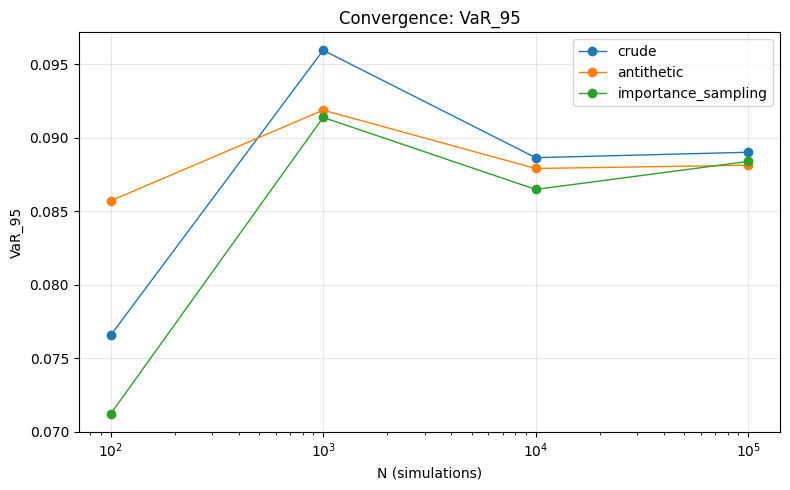

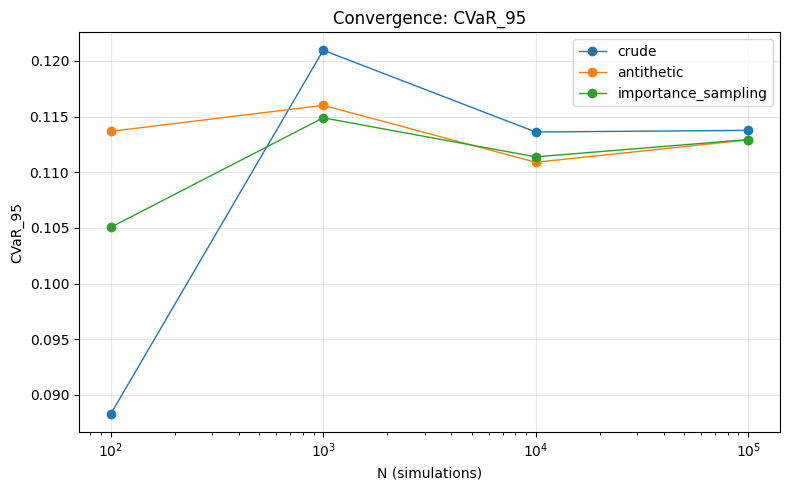

In [65]:
p7.show_convergence(phase7_results)


In [66]:
p7.save_outputs(phase7_results, 'phase7_outputs.pkl', 'phase7_summary_table.csv')


Saved: phase7_outputs.pkl
Saved: phase7_summary_table.csv


### 📝 Phase 7 summary — Variance reduction

**What I did:** Applied antithetic variates, control variates, and importance sampling, and measured the variance reduction factor (VRF) and effective sample size (ESS).

**What the output means:** A VRF > 1 means the method reaches the same accuracy with fewer simulations. The table shows which technique is most efficient for estimating the tail-risk metrics.

# Phase 8

In [67]:
cfg8 = p8.Phase8Config(B=500, seed=42, horizon_days=10, alphas=(0.95, 0.99),
    mc_enabled=True, mc_candidates=4000, mc_sims=5000, mc_alpha=0.95)
phase8_results = p8.run_phase8(R_train=R_train, base_weights=weights, cfg=cfg8,
    save_dir='outputs/phase8', prefix='phase8')


In [68]:
p8.save_outputs(phase8_results, 'outputs/phase8/phase8_outputs.pkl')


Saved: outputs/phase8/phase8_outputs.pkl


 Weight stability (95% intervals)

markowitz_max_sharpe — per-asset summary:


,mean,std,p2.5,p97.5
amazon,0.044538,0.124387,0.0,0.422987
apple,0.231575,0.293695,0.0,1.000000
exxon_mobil,0.178611,0.238789,0.0,0.897326
johnson_and_johnson,0.077719,0.177565,0.0,0.617471
microsoft,0.257677,0.314801,0.0,1.000000
visa,0.038100,0.131540,0.0,0.483924
walmart,0.171779,0.250915,0.0,0.834331


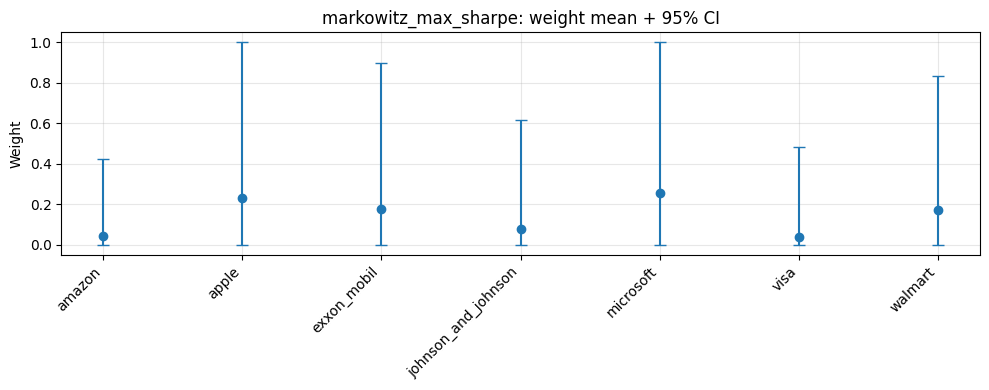


mc_max_sharpe — per-asset summary:


,mean,std,p2.5,p97.5
amazon,0.066902,0.121558,0.000798,0.468149
apple,0.219112,0.240073,0.002034,0.752422
exxon_mobil,0.178617,0.221302,0.001036,0.768807
johnson_and_johnson,0.092509,0.154755,0.001121,0.606147
microsoft,0.205531,0.233546,0.002492,0.769817
visa,0.066642,0.132121,0.000793,0.530400
walmart,0.170687,0.214280,0.001218,0.728410


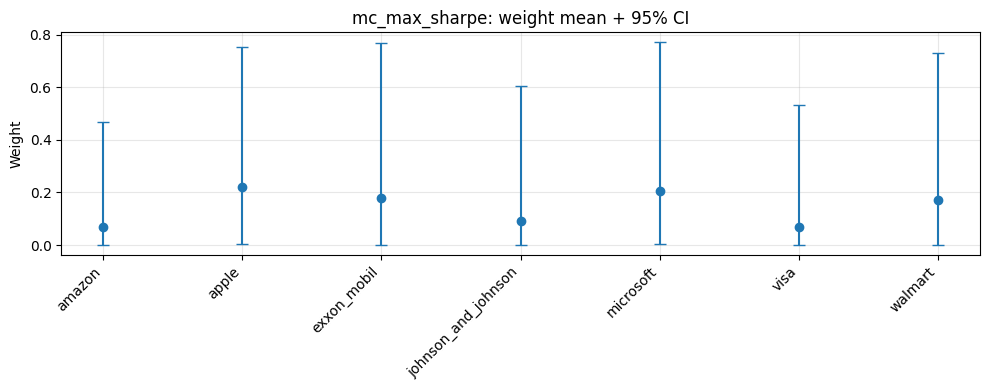


mc_min_cvar — per-asset summary:


,mean,std,p2.5,p97.5
amazon,0.059373,0.040001,0.004326,0.145375
apple,0.027854,0.024845,0.001015,0.087990
exxon_mobil,0.082864,0.045982,0.009818,0.179572
johnson_and_johnson,0.442777,0.093832,0.256491,0.630078
microsoft,0.034143,0.030477,0.001023,0.116866
visa,0.044333,0.038776,0.000887,0.146081
walmart,0.308656,0.094293,0.120682,0.508149


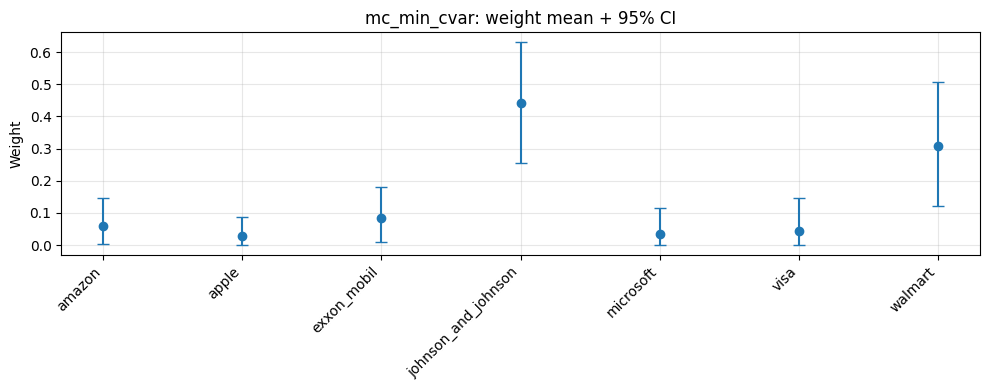


 Weight stability plots (box/violin/hist)


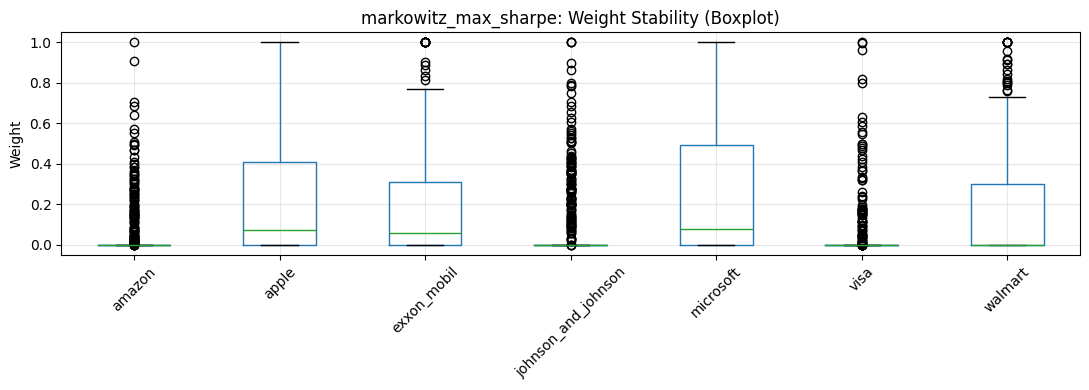

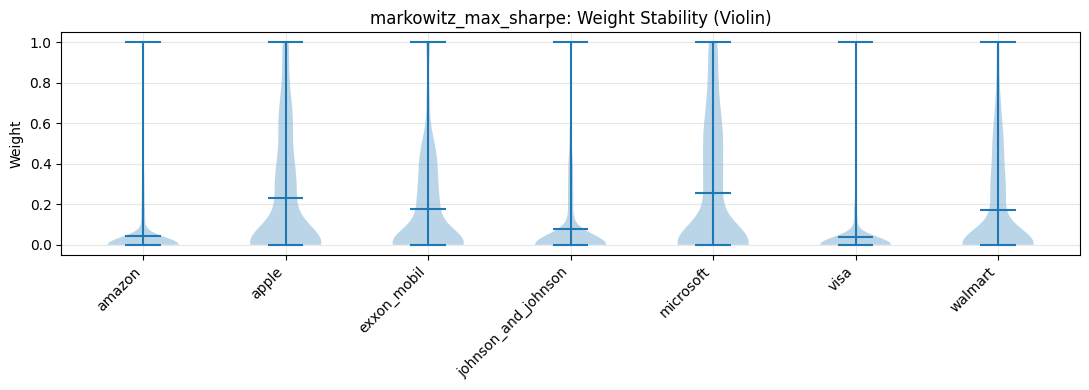

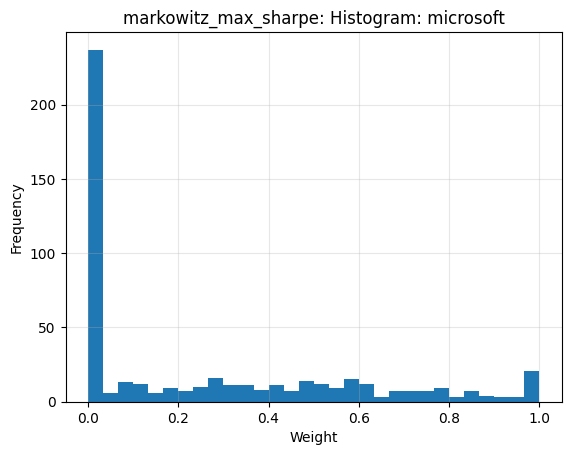

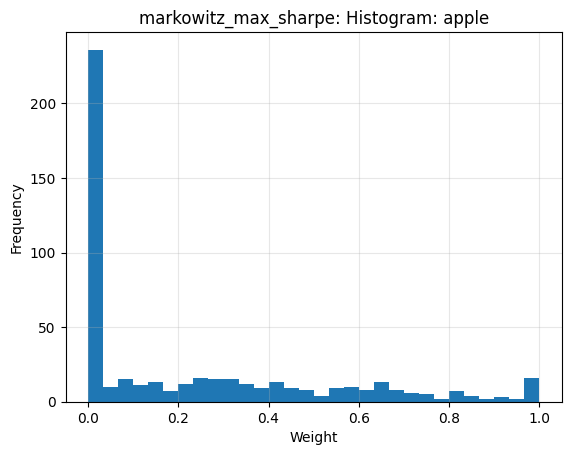

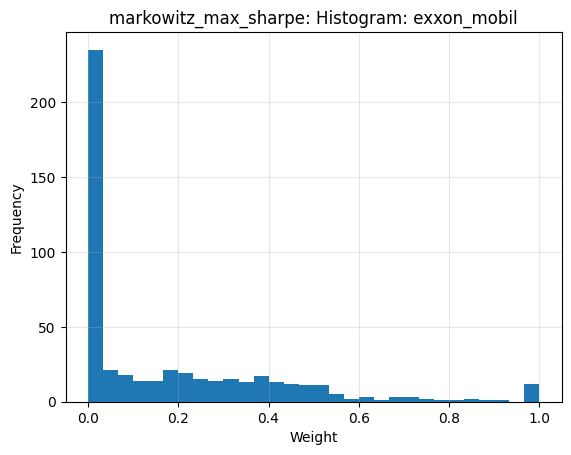

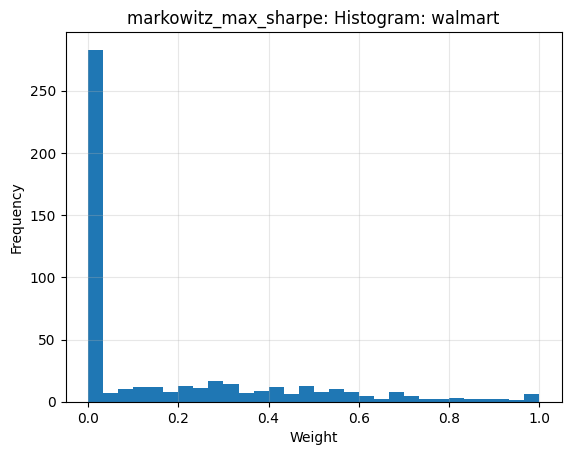

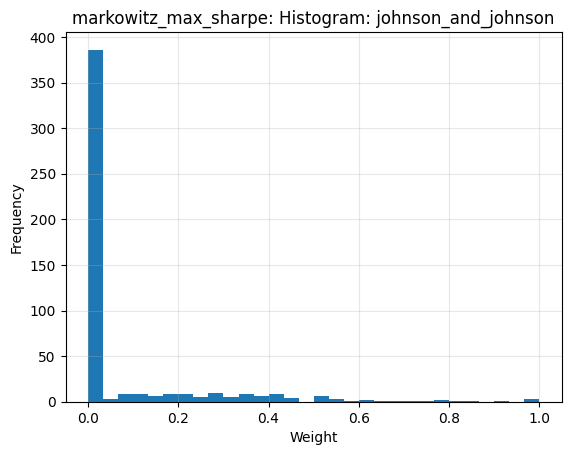

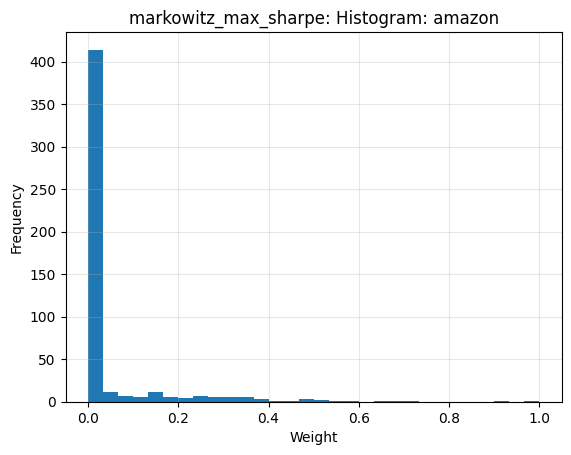

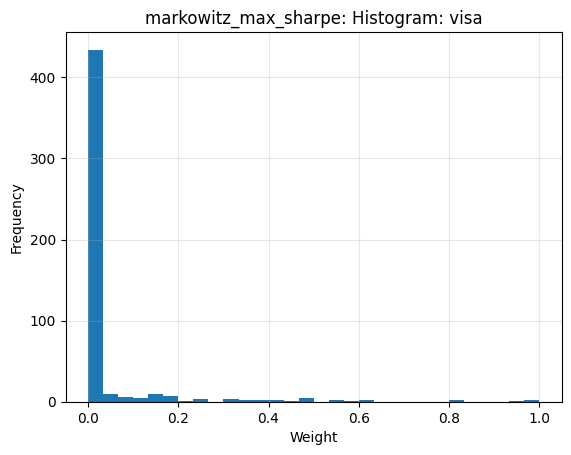

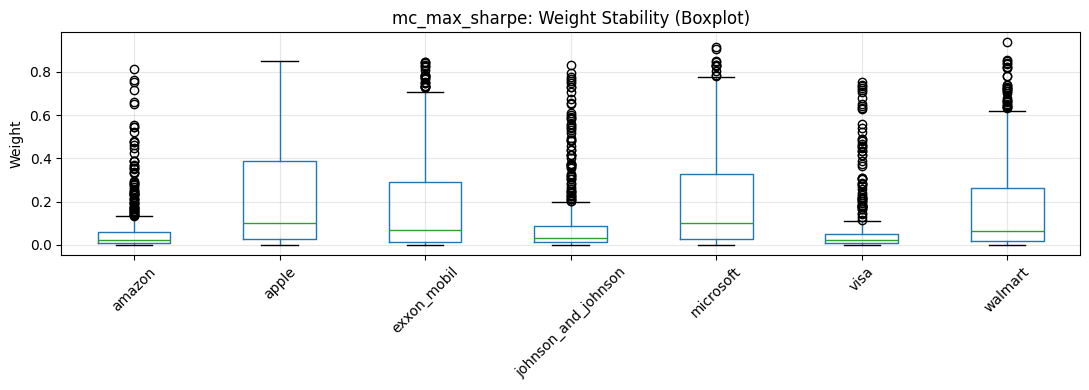

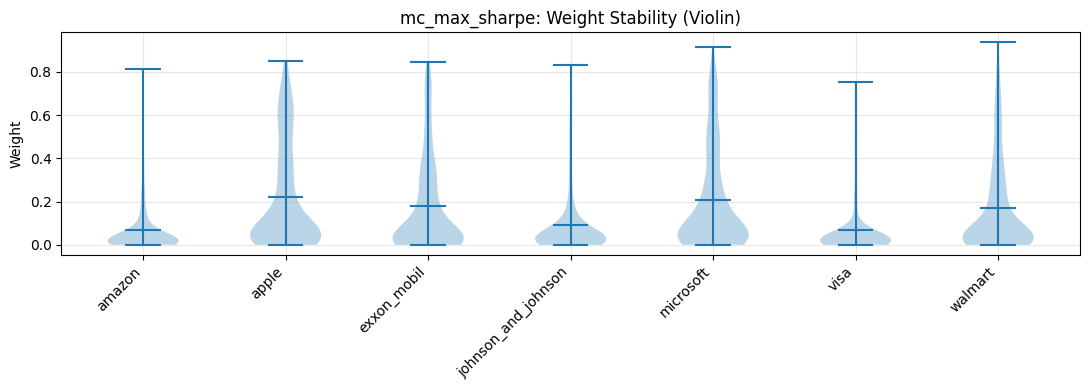

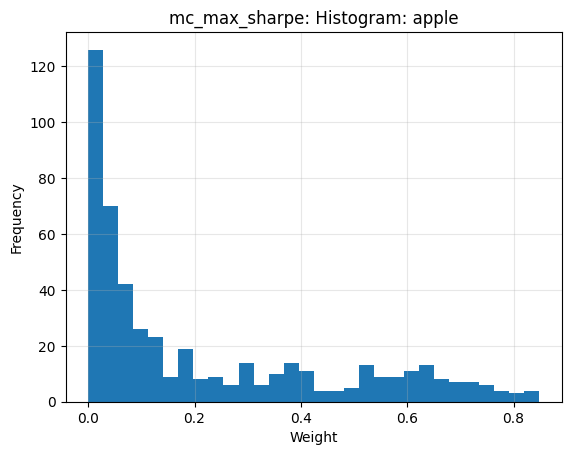

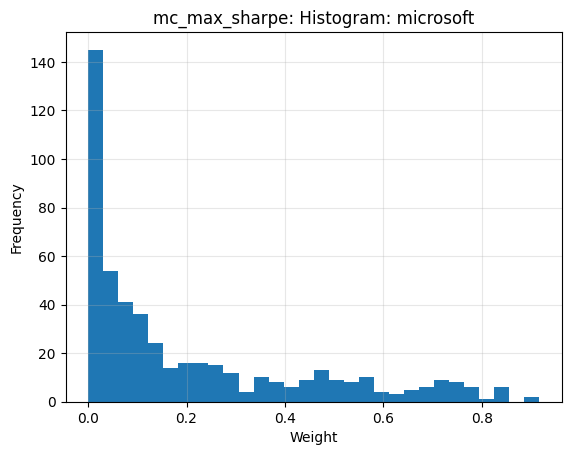

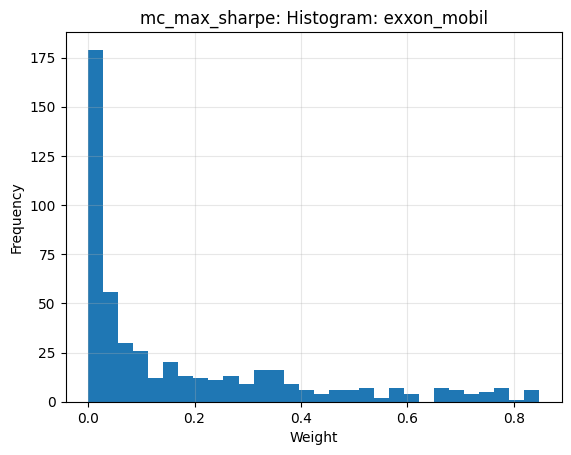

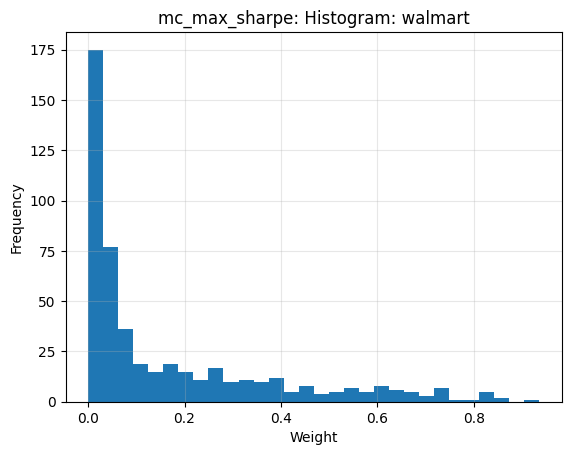

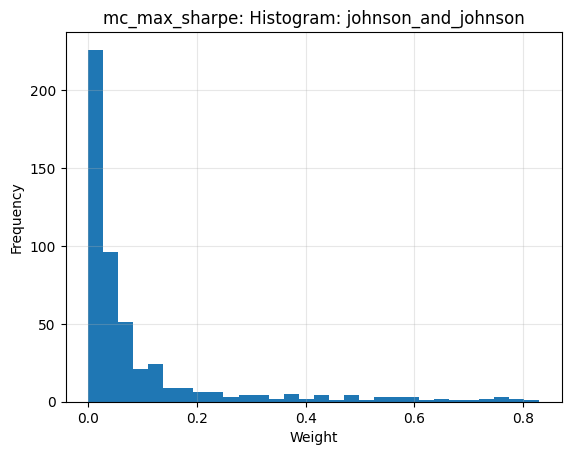

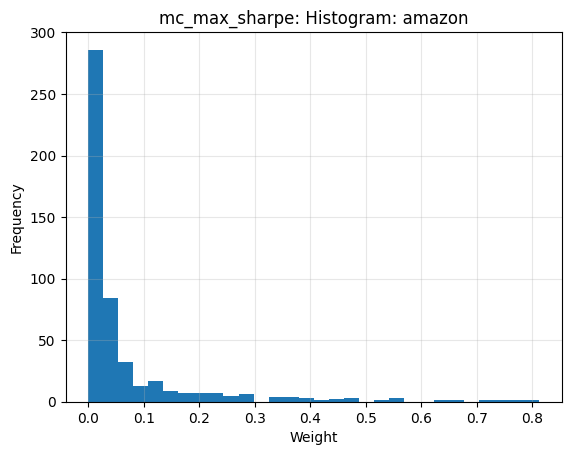

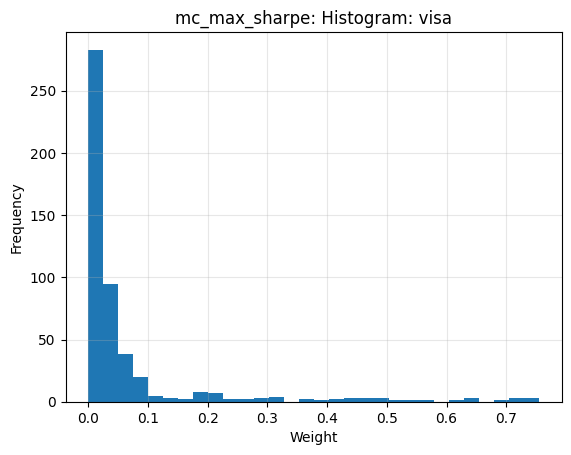

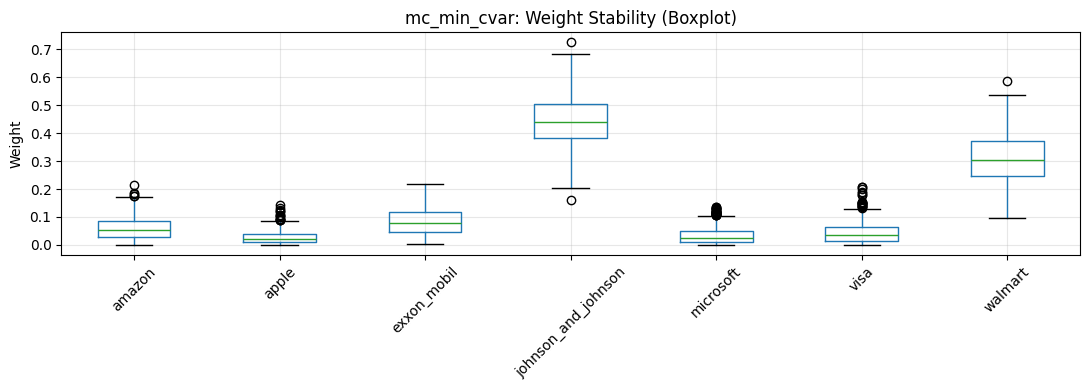

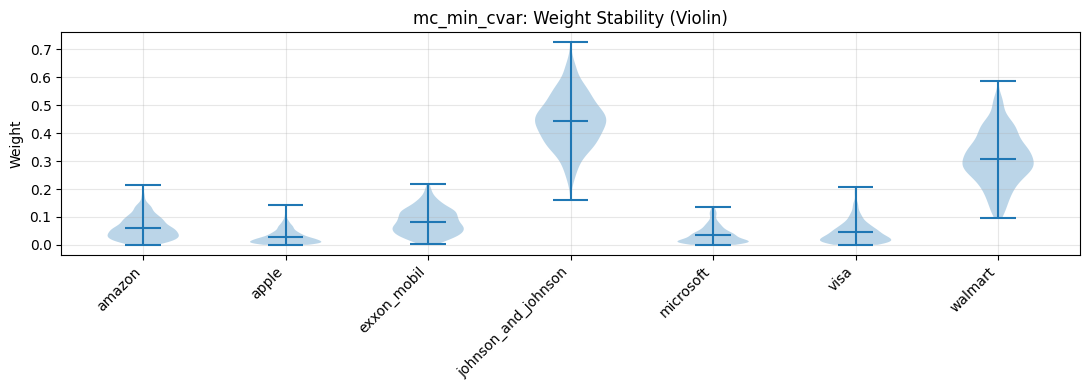

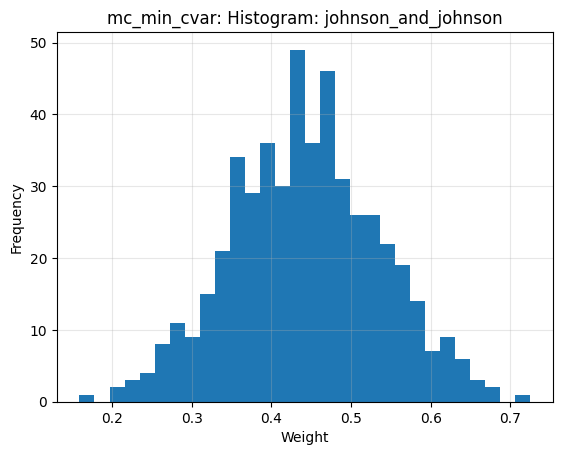

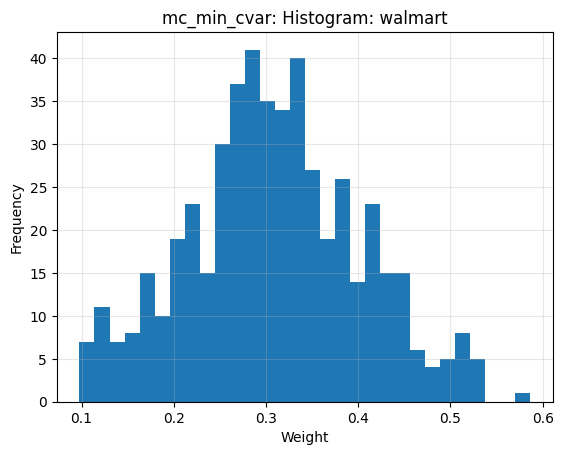

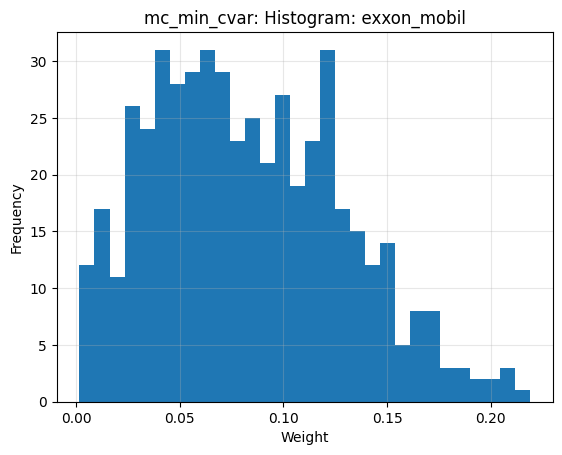

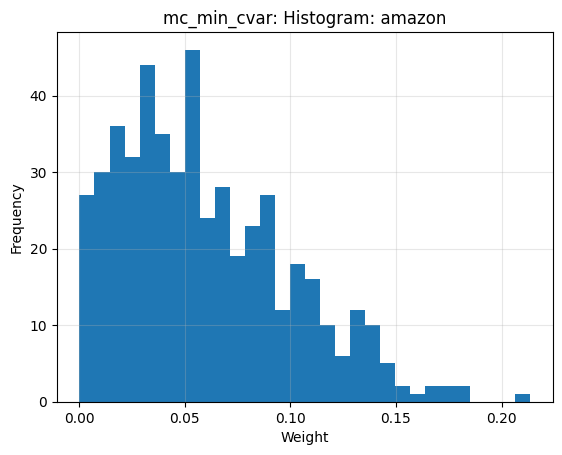

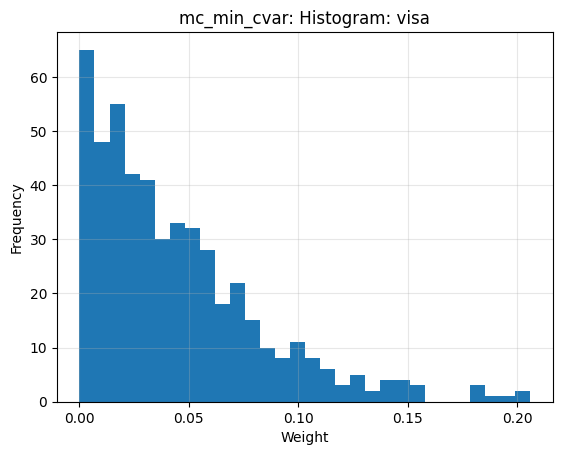

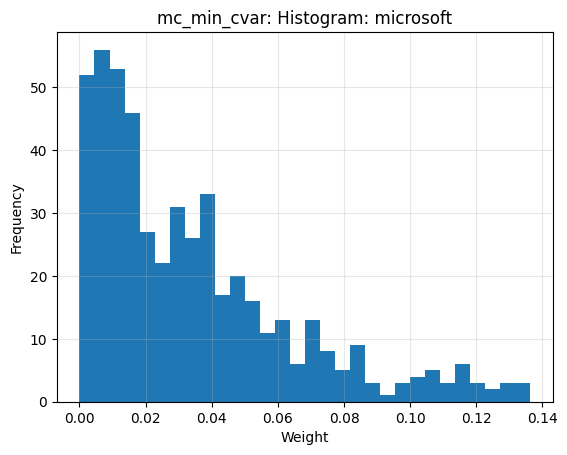

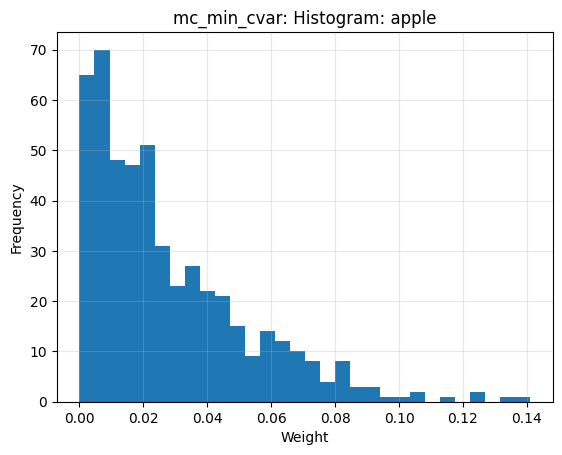

In [69]:
p8.show_weight_stability(phase8_results)


In [70]:
p8.report_turnover_and_risk(phase8_results)



Phase 8 — Turnover proxy distribution


,count,mean,std,min,25%,50%,75%,max
portfolio,,,,,,,,
markowitz_max_sharpe,500.0,0.573425,0.188045,0.083614,0.457416,0.555224,0.680109,1.000000
mc_max_sharpe,500.0,0.611039,0.224196,0.054301,0.448813,0.691522,0.773869,0.950509
mc_min_cvar,500.0,0.215357,0.078720,0.046090,0.156368,0.209616,0.265671,0.499011



Phase 8 — Risk metrics under bootstrapped parameters


mu_h                       sigma_h            \
                          mean       std    median      mean       std   
portfolio                                                                
markowitz_max_sharpe  0.011532  0.005478  0.011191  0.054018  0.009474   
mc_max_sharpe         0.010107  0.005407  0.010021  0.051664  0.007859   
mc_min_cvar           0.003823  0.003927  0.003752  0.036589  0.002004   

                                sharpe_h                        VaR_95  ...  \
                        median      mean       std    median      mean  ...   
portfolio                                                               ...   
markowitz_max_sharpe  0.054543  0.217318  0.099310  0.216312  0.077319  ...   
mc_max_sharpe         0.052459  0.197526  0.102125  0.195228  0.074873  ...   
mc_min_cvar           0.036698  0.104938  0.107386  0.101258  0.056361  ...   

                                 CVaR_95                        VaR_99  \
                        median      mean       std    median      mean   
portfolio                                                                
markowitz_max_sharpe  0.075578  0.099890  0.019659  0.097950  0.114131   
mc_max_sharpe         0.074945  0.096462  0.016273  0.096851  0.110082   
mc_min_cvar           0.056443  0.071650  0.005771  0.071591  0.081296   

                                           CVaR_99                      
                           std    median      mean       std    median  
portfolio                                                               
markowitz_max_sharpe  0.022070  0.111921  0.132436  0.025194  0.130390  
mc_max_sharpe         0.018243  0.110932  0.127590  0.020804  0.128760  
mc_min_cvar           0.006169  0.081390  0.093695  0.006707  0.093664  

[3 rows x 21 columns]

In [71]:
p8.report_ci_and_commentary(phase8_results)



Phase 8 — CI bands table for VaR/CVaR


,portfolio,metric,mean,std,p_lo,p_hi,ci_width
0,markowitz_max_sharpe,CVaR_95,0.099890,0.019659,0.069103,0.143142,0.074039
1,markowitz_max_sharpe,CVaR_99,0.132436,0.025194,0.092868,0.186124,0.093256
2,markowitz_max_sharpe,VaR_95,0.077319,0.015892,0.052391,0.113247,0.060855
3,markowitz_max_sharpe,VaR_99,0.114131,0.022070,0.079656,0.161920,0.082264
4,mc_max_sharpe,CVaR_95,0.096462,0.016273,0.068387,0.126544,0.058157
5,mc_max_sharpe,CVaR_99,0.127590,0.020804,0.090506,0.165891,0.075385
6,mc_max_sharpe,VaR_95,0.074873,0.013215,0.052671,0.099493,0.046821
7,mc_max_sharpe,VaR_99,0.110082,0.018243,0.078198,0.143472,0.065274
8,mc_min_cvar,CVaR_95,0.071650,0.005771,0.061185,0.083020,0.021835
9,mc_min_cvar,CVaR_99,0.093695,0.006707,0.081207,0.107099,0.025892



Phase 8 — Commentary (slide-ready)
Parameter-uncertainty commentary (bootstrap):
- Bootstrap draws: B=500, horizon=10 days.
- Re-estimating μ and Σ across resamples produces a distribution of optimal weights and risk metrics.
- markowitz_max_sharpe: highest weight dispersion in microsoft (sd=0.315), apple (sd=0.294).
- mc_max_sharpe: highest weight dispersion in apple (sd=0.240), microsoft (sd=0.234).
- mc_min_cvar: highest weight dispersion in walmart (sd=0.094), johnson_and_johnson (sd=0.094).
- markowitz_max_sharpe: turnover proxy mean=0.573 (sd=0.188); higher means less stable allocations.
- mc_max_sharpe: turnover proxy mean=0.611 (sd=0.224); higher means less stable allocations.
- mc_min_cvar: turnover proxy mean=0.215 (sd=0.079); higher means less stable allocations.
- markowitz_max_sharpe: VaR_95 95% CI width=0.0609 (relative ≈ 78.7%).
- mc_max_sharpe: VaR_95 95% CI width=0.0468 (relative ≈ 62.5%).
- mc_min_cvar: VaR_95 95% CI width=0.0196 (relative ≈ 34.7%).
- Takeaway: param

## Phase 8b — Bayesian parameter uncertainty (Gibbs / Normal-Inverse-Wishart)

Frequentist (plug-in) vs Bayesian (posterior-averaged) Max-Sharpe weights:


,Asset,Frequentist_MaxSharpe,Bayesian_MaxSharpe,Diff
0,amazon,0.0000,0.0509,0.0509
1,apple,0.5255,0.2222,-0.3033
2,exxon_mobil,0.1222,0.2270,0.1048
3,johnson_and_johnson,0.0000,0.0384,0.0384
4,microsoft,0.3523,0.2763,-0.0760
5,visa,0.0000,0.0175,0.0175
6,walmart,0.0000,0.1677,0.1677


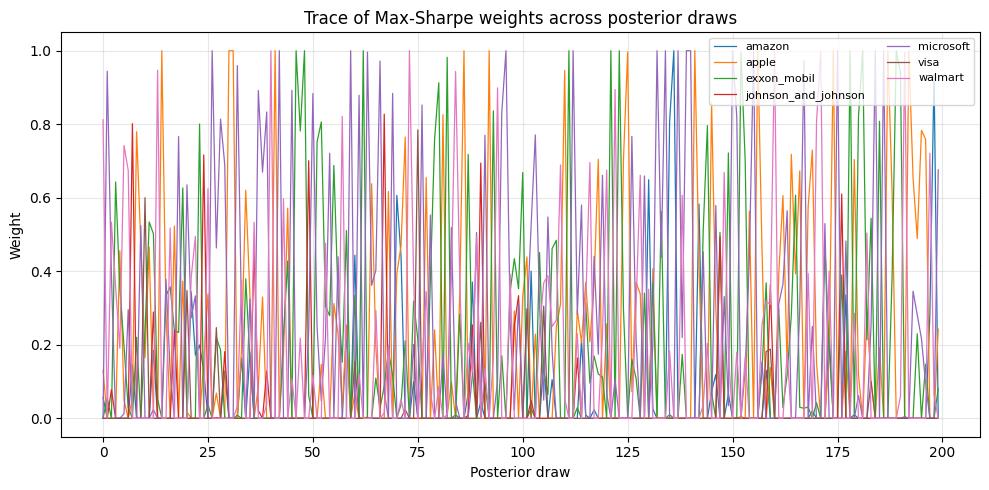

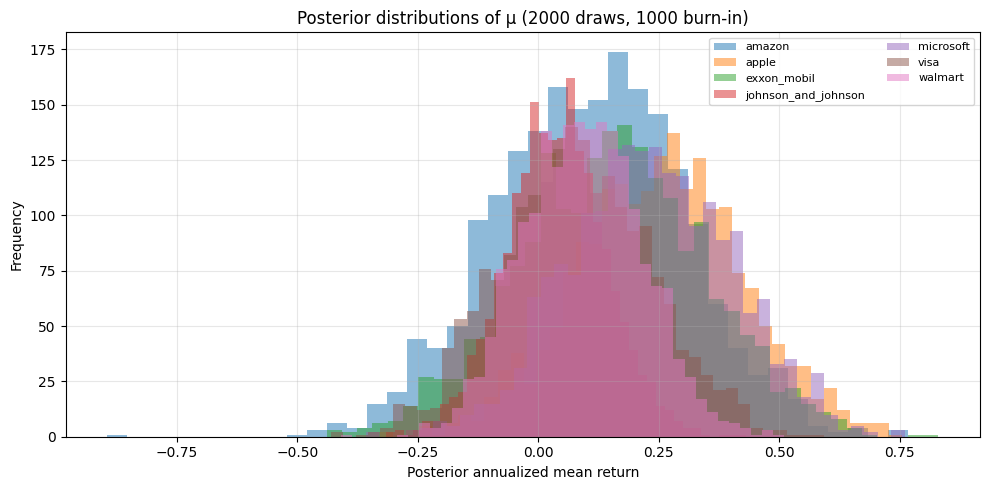

In [72]:
bayes = p8.bayesian_gibbs(R_train, risk_free=0.04,
    n_iter=3000, burn_in=1000, n_portfolio_draws=200, seed=42)
p8.report_bayesian(bayes)


### 📝 Phase 8 summary — Parameter uncertainty (bootstrap + Bayesian)

**What I did:** Quantified how uncertain the optimal weights and risk metrics are — first by bootstrapping the returns, then via a Bayesian (Normal-Inverse-Wishart / Gibbs) posterior.

**What the output means:** The CI bands and weight box/violin plots show the optimal portfolio is **not** a single precise answer — small changes in the data move the weights. The Bayesian posteriors and weight traces show the same uncertainty from a probabilistic angle.

# Phase 9

In [73]:
portfolios = p9.build_portfolios(
    max_sharpe_weights_mv=max_sharpe_weights_mv,
    min_vol_weights_mv=min_vol_weights_mv, mc_results=mc_results)
cfg9 = p9.Phase9Config(trading_days=252, horizon_days=10, alphas=(0.95, 0.99),
    exceedance_horizon_days=1, stress_enabled=True, stress_worst_pct=0.05, save_plots=True)
phase9_results = p9.run_phase9(R_train=R_train, R_test=R_test, mu_daily=mu_daily,
    sigma_daily=sigma_daily, portfolios=portfolios, cfg=cfg9,
    save_dir='outputs/phase9', prefix='phase9')


,portfolio,alpha,horizon_days,oos_return_ann,oos_vol_ann,VaR_pred,CVaR_pred,VaR_real,CVaR_real,VaR_exceed_rate,VaR_exceed_target
0,MC_MaxSharpe,0.95,10,0.191134,0.169203,0.088461,0.113185,0.044477,0.055457,0.004082,0.05
1,MC_MaxSharpe,0.99,10,0.191134,0.169203,0.128783,0.148833,0.059326,0.070829,0.000000,0.01
2,MC_MinCVaR,0.95,10,0.221704,0.106584,0.056967,0.072087,0.019321,0.028095,0.004082,0.05
3,MC_MinCVaR,0.99,10,0.221704,0.106584,0.081626,0.093888,0.035201,0.039156,0.000000,0.01
4,Markowitz_MaxSharpe,0.95,10,0.171004,0.162624,0.088265,0.112989,0.043477,0.054494,0.008163,0.05
5,Markowitz_MaxSharpe,0.99,10,0.171004,0.162624,0.128588,0.148639,0.059709,0.072114,0.000000,0.01
6,Markowitz_MinVol,0.95,10,0.246668,0.106291,0.056680,0.071738,0.017744,0.025571,0.004082,0.05
7,Markowitz_MinVol,0.99,10,0.246668,0.106291,0.081239,0.093450,0.031808,0.035136,0.000000,0.01


CVaR_pred           CVaR_real           VaR_exceed_rate  \
alpha                    0.95      0.99      0.95      0.99            0.95   
portfolio                                                                     
MC_MaxSharpe         0.113185  0.148833  0.055457  0.070829        0.004082   
MC_MinCVaR           0.072087  0.093888  0.028095  0.039156        0.004082   
Markowitz_MaxSharpe  0.112989  0.148639  0.054494  0.072114        0.008163   
Markowitz_MinVol     0.071738  0.093450  0.025571  0.035136        0.004082   

                         VaR_exceed_target        VaR_pred            \
alpha               0.99              0.95  0.99      0.95      0.99   
portfolio                                                              
MC_MaxSharpe         0.0              0.05  0.01  0.088461  0.128783   
MC_MinCVaR           0.0              0.05  0.01  0.056967  0.081626   
Markowitz_MaxSharpe  0.0              0.05  0.01  0.088265  0.128588   
Markowitz_MinVol     0.0              0.05  0.01  0.056680  0.081239   

                     VaR_real            
alpha                    0.95      0.99  
portfolio                                
MC_MaxSharpe         0.044477  0.059326  
MC_MinCVaR           0.019321  0.035201  
Markowitz_MaxSharpe  0.043477  0.059709  
Markowitz_MinVol     0.017744  0.031808

<Figure size 1100x500 with 0 Axes>

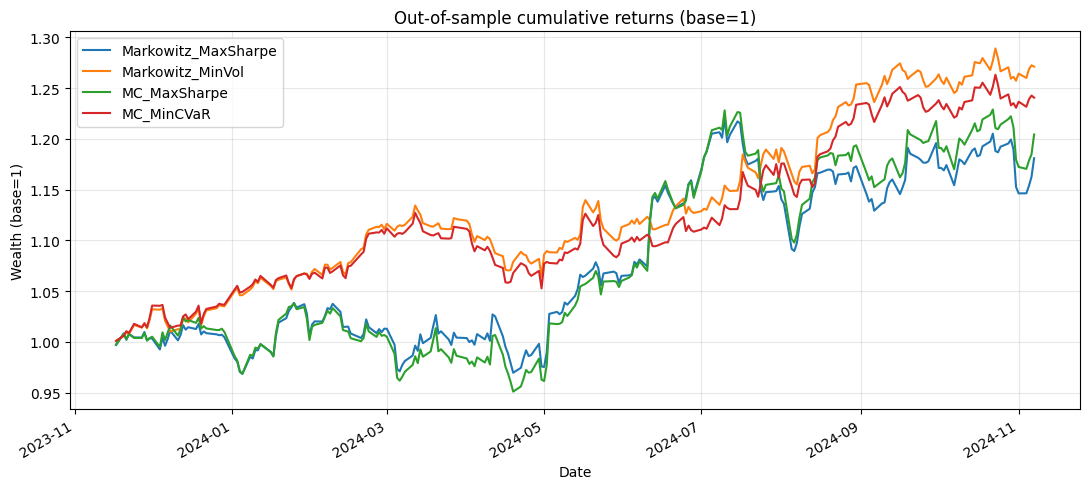

In [74]:
metrics = p9.report_and_plot_metrics(phase9_results)


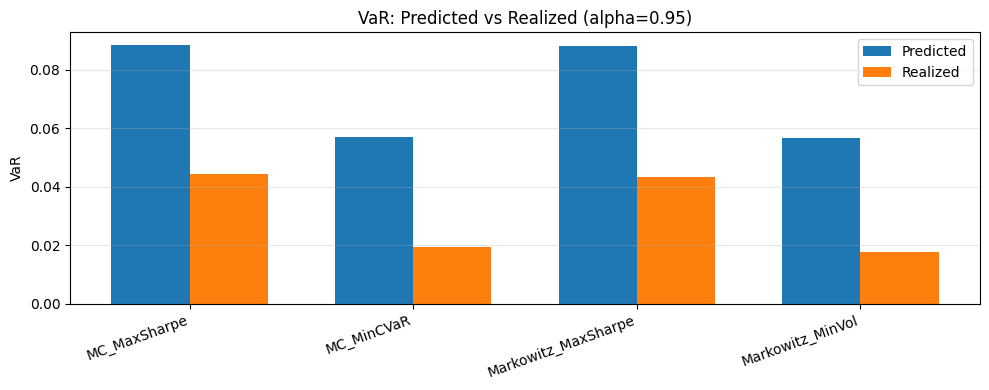

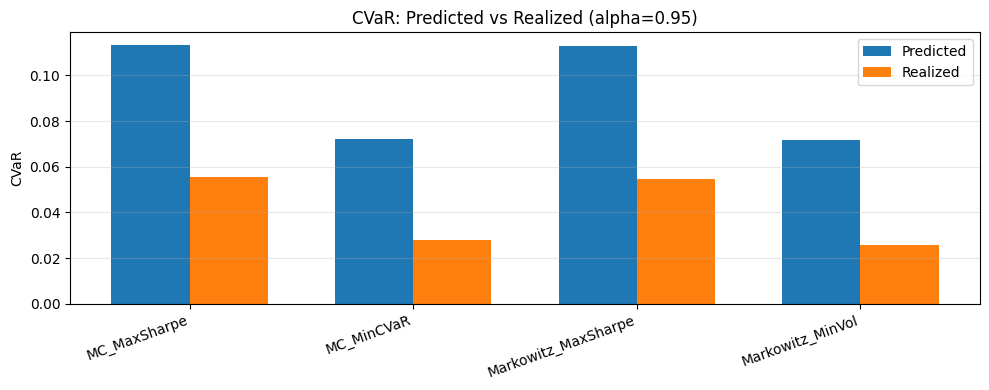

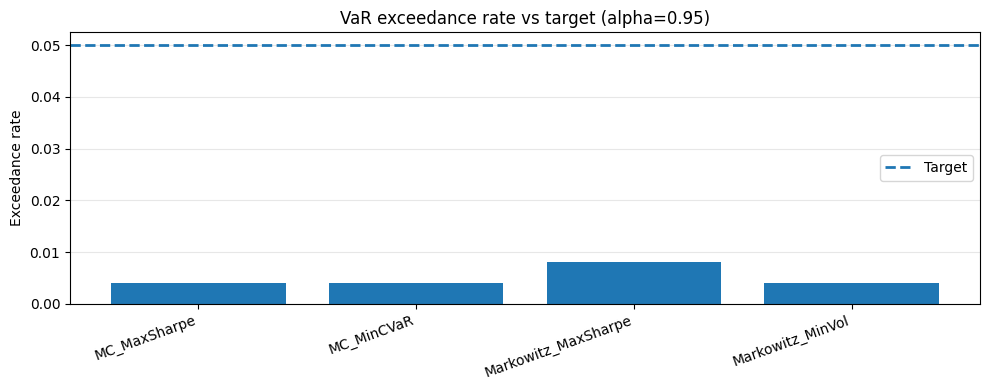

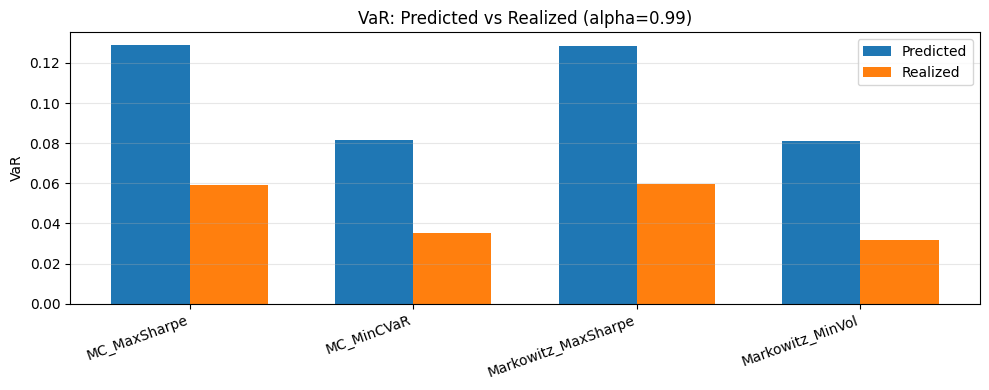

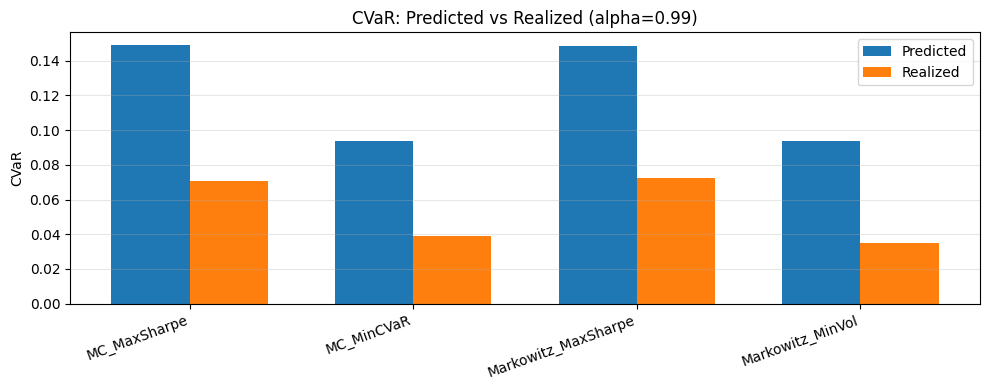

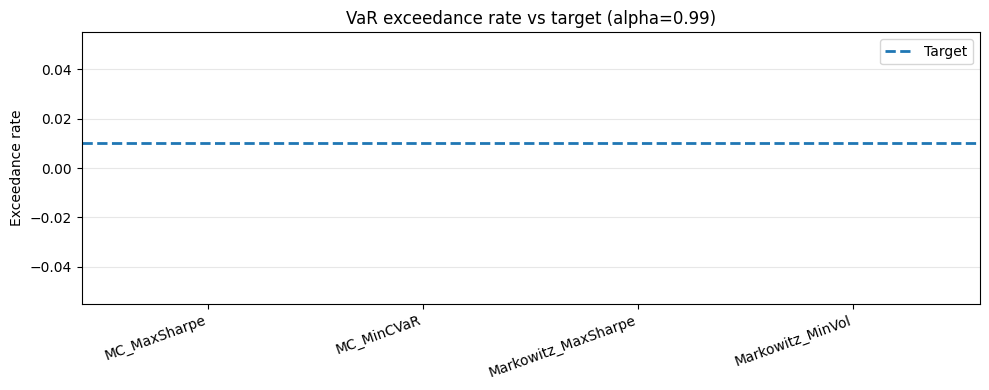

In [75]:
p9.show_pred_real_exceedance(metrics, cfg9.alphas)


## Phase 9b — VaR backtests (Kupiec POF + Christoffersen)

In [76]:
var_backtests = p9.run_var_backtests(R_test, mu_daily, sigma_daily, portfolios, cfg9)
p9.report_var_backtests(var_backtests)


VaR backtests (p<0.05 => reject the VaR model at that level):
  Kupiec POF        = correct NUMBER of exceedances (unconditional coverage)
  Christoffersen    = exceedances are INDEPENDENT (no clustering)
  Cond. coverage    = both jointly


,portfolio,alpha,n_obs,exceedances,expected,Kupiec_pvalue,Christoffersen_pvalue,CondCoverage_pvalue
0,MC_MaxSharpe,0.95,245,1,12.25,0.000,0.928,0.000
1,MC_MaxSharpe,0.99,245,0,2.45,0.026,1.000,0.085
2,MC_MinCVaR,0.95,245,1,12.25,0.000,0.928,0.000
3,MC_MinCVaR,0.99,245,0,2.45,0.026,1.000,0.085
4,Markowitz_MaxSharpe,0.95,245,2,12.25,0.000,0.856,0.001
5,Markowitz_MaxSharpe,0.99,245,0,2.45,0.026,1.000,0.085
6,Markowitz_MinVol,0.95,245,1,12.25,0.000,0.928,0.000
7,Markowitz_MinVol,0.99,245,0,2.45,0.026,1.000,0.085


,portfolio,alpha,n_obs,exceedances,expected,Kupiec_pvalue,Christoffersen_pvalue,CondCoverage_pvalue
0,MC_MaxSharpe,0.95,245,1,12.25,0.000,0.928,0.000
1,MC_MaxSharpe,0.99,245,0,2.45,0.026,1.000,0.085
2,MC_MinCVaR,0.95,245,1,12.25,0.000,0.928,0.000
3,MC_MinCVaR,0.99,245,0,2.45,0.026,1.000,0.085
4,Markowitz_MaxSharpe,0.95,245,2,12.25,0.000,0.856,0.001
5,Markowitz_MaxSharpe,0.99,245,0,2.45,0.026,1.000,0.085
6,Markowitz_MinVol,0.95,245,1,12.25,0.000,0.928,0.000
7,Markowitz_MinVol,0.99,245,0,2.45,0.026,1.000,0.085


In [77]:
p9.report_stress(phase9_results)


Stress subset = worst days (by 1-day portfolio loss)


,portfolio,subset,n_days,mean_ann_subset,vol_ann_subset,avg_loss_subset,max_loss_subset,mean_ann_normal,vol_ann_normal,avg_loss_normal,max_loss_normal,delta_mean_ann,delta_vol_ann,delta_avg_loss
0,MC_MaxSharpe,worst_5pct_global,12,-4.743839,0.162748,0.018825,0.041465,0.445296,0.153618,-0.001767,0.024107,-5.189135,0.009130,0.020592
1,MC_MinCVaR,worst_5pct_global,12,-2.033221,0.143364,0.008068,0.019168,0.337838,0.099377,-0.001341,0.013340,-2.371058,0.043987,0.009409
2,Markowitz_MaxSharpe,worst_5pct_global,12,-4.887737,0.159751,0.019396,0.039865,0.431540,0.145193,-0.001712,0.024247,-5.319278,0.014558,0.021108
3,Markowitz_MinVol,worst_5pct_global,12,-2.089340,0.135097,0.008291,0.018699,0.366977,0.099192,-0.001456,0.012882,-2.456317,0.035905,0.009747


### 📝 Phase 9 summary — Validation & backtesting

**What I did:** Applied the in-sample optimal portfolios to the held-out test data, compared predicted vs realized VaR/CVaR, ran the Kupiec and Christoffersen backtests, and stress-tested on the worst days.

**What the output means:** The exceedance rates and backtest p-values judge whether the VaR model is well-calibrated out-of-sample. Here the Normal VaR is **too conservative** (far fewer breaches than expected), and Christoffersen shows the breaches are not clustered.